In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, wasserstein_distance, ks_2samp, pearsonr, spearmanr
import glob
import os
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import AutoMinorLocator
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import os
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import matplotlib.colors as mcolors


In [2]:
from picosvg.svg import SVG

def save_flat_svg(fig, path, dpi=500):
    fig.savefig(path, dpi=dpi)
    svg = SVG.parse(path).topicosvg()
    with open(path, "w") as f:
        f.write(svg.tostring())

In [3]:
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
})

plt.rcParams['font.family'] = 'Arial'


# Figure Panel #6

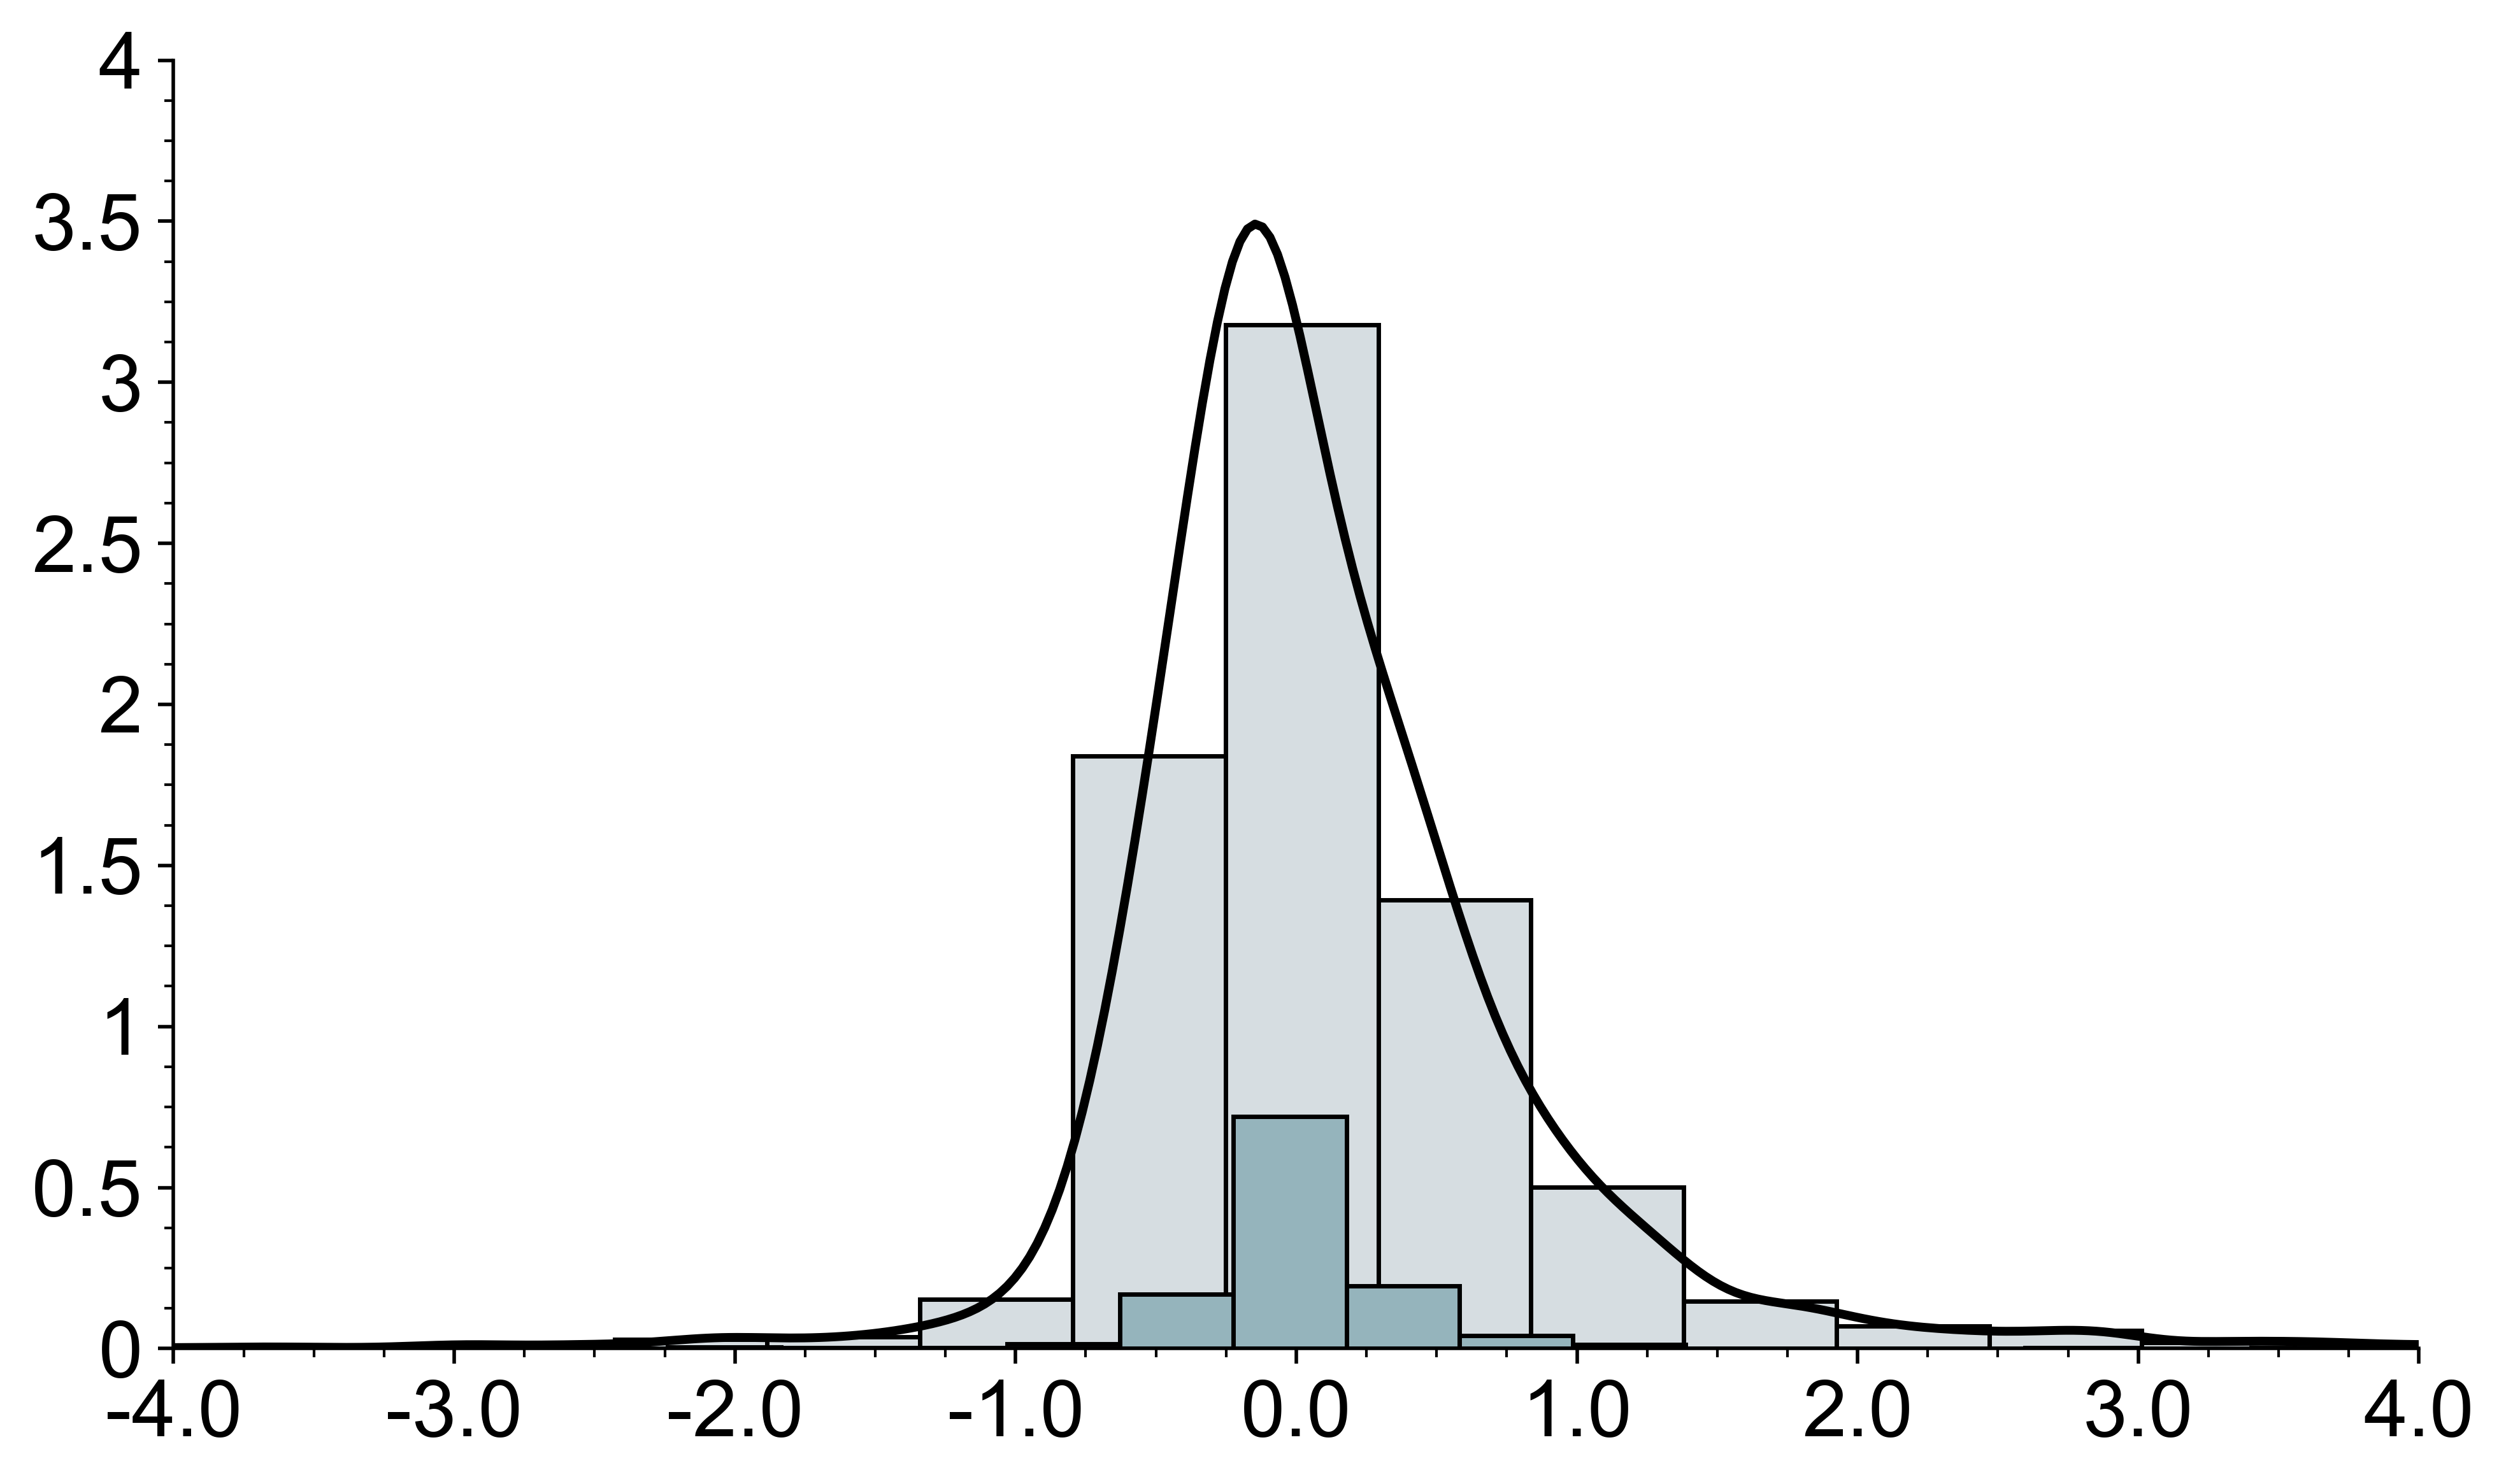

In [4]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

color3_ramp = ["#F5F8F9", "#E8EFF2", "#D8E9F0", "#AECDDA", "#84B7CD",
               "#61A5C2", "#4590B0", "#3A748D", "#305869", "#26404B", "#1A272D"]

HIST_COLOR = "#D6DDE1"
KDE_COLOR = "black"
PDPT_HIST_COLOR = "#95B4BC"


def load_binding_energies(file):
    df = pd.read_csv(file)
    if "computed_binding_E" not in df.columns:
        raise KeyError("Expected column 'computed_binding_E' not found in CSV")
    energies = df["computed_binding_E"].dropna().to_numpy() + 0.27
    if energies.size == 0:
        raise ValueError("No valid (non-NaN) computed_binding_E values found")
    return energies, df


def load_pdpt_energies(file):
    df = pd.read_csv(file)
    energies = df["Binding_Energy_eV"].dropna().to_numpy() + 0.27
    return energies


def plot_distribution(energies, pdpt_energies, output_path):
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    n_bins = min(30, max(10, int(np.sqrt(len(energies)))))
    counts, bin_edges, _ = ax.hist(
        energies, bins=n_bins, density=False,
        color=HIST_COLOR, edgecolor="black", label="Binding energy"
    )
    bin_width = bin_edges[1] - bin_edges[0]
    if len(energies) > 1:
        kde = gaussian_kde(energies)
        x = np.linspace(max(energies.min(), -4), min(energies.max(), 4), 300)
        ax.plot(x, kde(x) * len(energies) * bin_width, color=KDE_COLOR, linewidth=2, label="KDE")

    n_bins_pdpt = min(30, max(10, int(np.sqrt(len(pdpt_energies)))))
    counts_pdpt, bin_edges_pdpt, _ = ax.hist(
        pdpt_energies, bins=n_bins_pdpt, density=False,
        color=PDPT_HIST_COLOR, edgecolor="black", label="Pd/Pt binding energy"
    )
    bin_width_pdpt = bin_edges_pdpt[1] - bin_edges_pdpt[0]

    #target_tol = 0.20 
    #for i, x0 in enumerate((-target_tol, target_tol)):
     #   ax.axvline(x0, color=TARGET_COLOR, linestyle="--", linewidth=1.5,
      #      label=f"±{target_tol:.2f} eV" if i == 0 else None)

    from matplotlib.ticker import FuncFormatter
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:g}"))

    from matplotlib.ticker import FormatStrFormatter
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))

    ax.xaxis.set_minor_locator(AutoMinorLocator(n=4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(n=4))
    ax.set_xlim(-4.0, 4.0)
    ax.set_ylim(0, 4000)
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    save_flat_svg(fig, output_path)


file = "/Users/deanmsweeney/Documents/CFM/gace/manuscript/data/H_volcano/relaxed_strucs_data.csv"
pdpt_file = os.path.join(os.path.dirname(file), "pd_pt_data.csv")
output_path = "./fig6/panel/binding_energy_dist.svg"

energies, df = load_binding_energies(file)
pdpt_energies = load_pdpt_energies(pdpt_file)
plot_distribution(energies, pdpt_energies, output_path)

2411 structures
  E_hull <= 0      (stable)                        276   11.4%
  E_hull <= 0.028    (stable or metastable)       1573   65.2%
  median E_hull: +0.0130 eV/atom
  known composition in MP: 1514 (62.8%)
  by number of elements:
    1: n=   99  <=0.1:  63.6%  median +0.0132
    2: n= 1394  <=0.1:  70.2%  median +0.0119
    3: n=  891  <=0.1:  59.3%  median +0.0153
    4: n=   27  <=0.1:  14.8%  median +0.2232


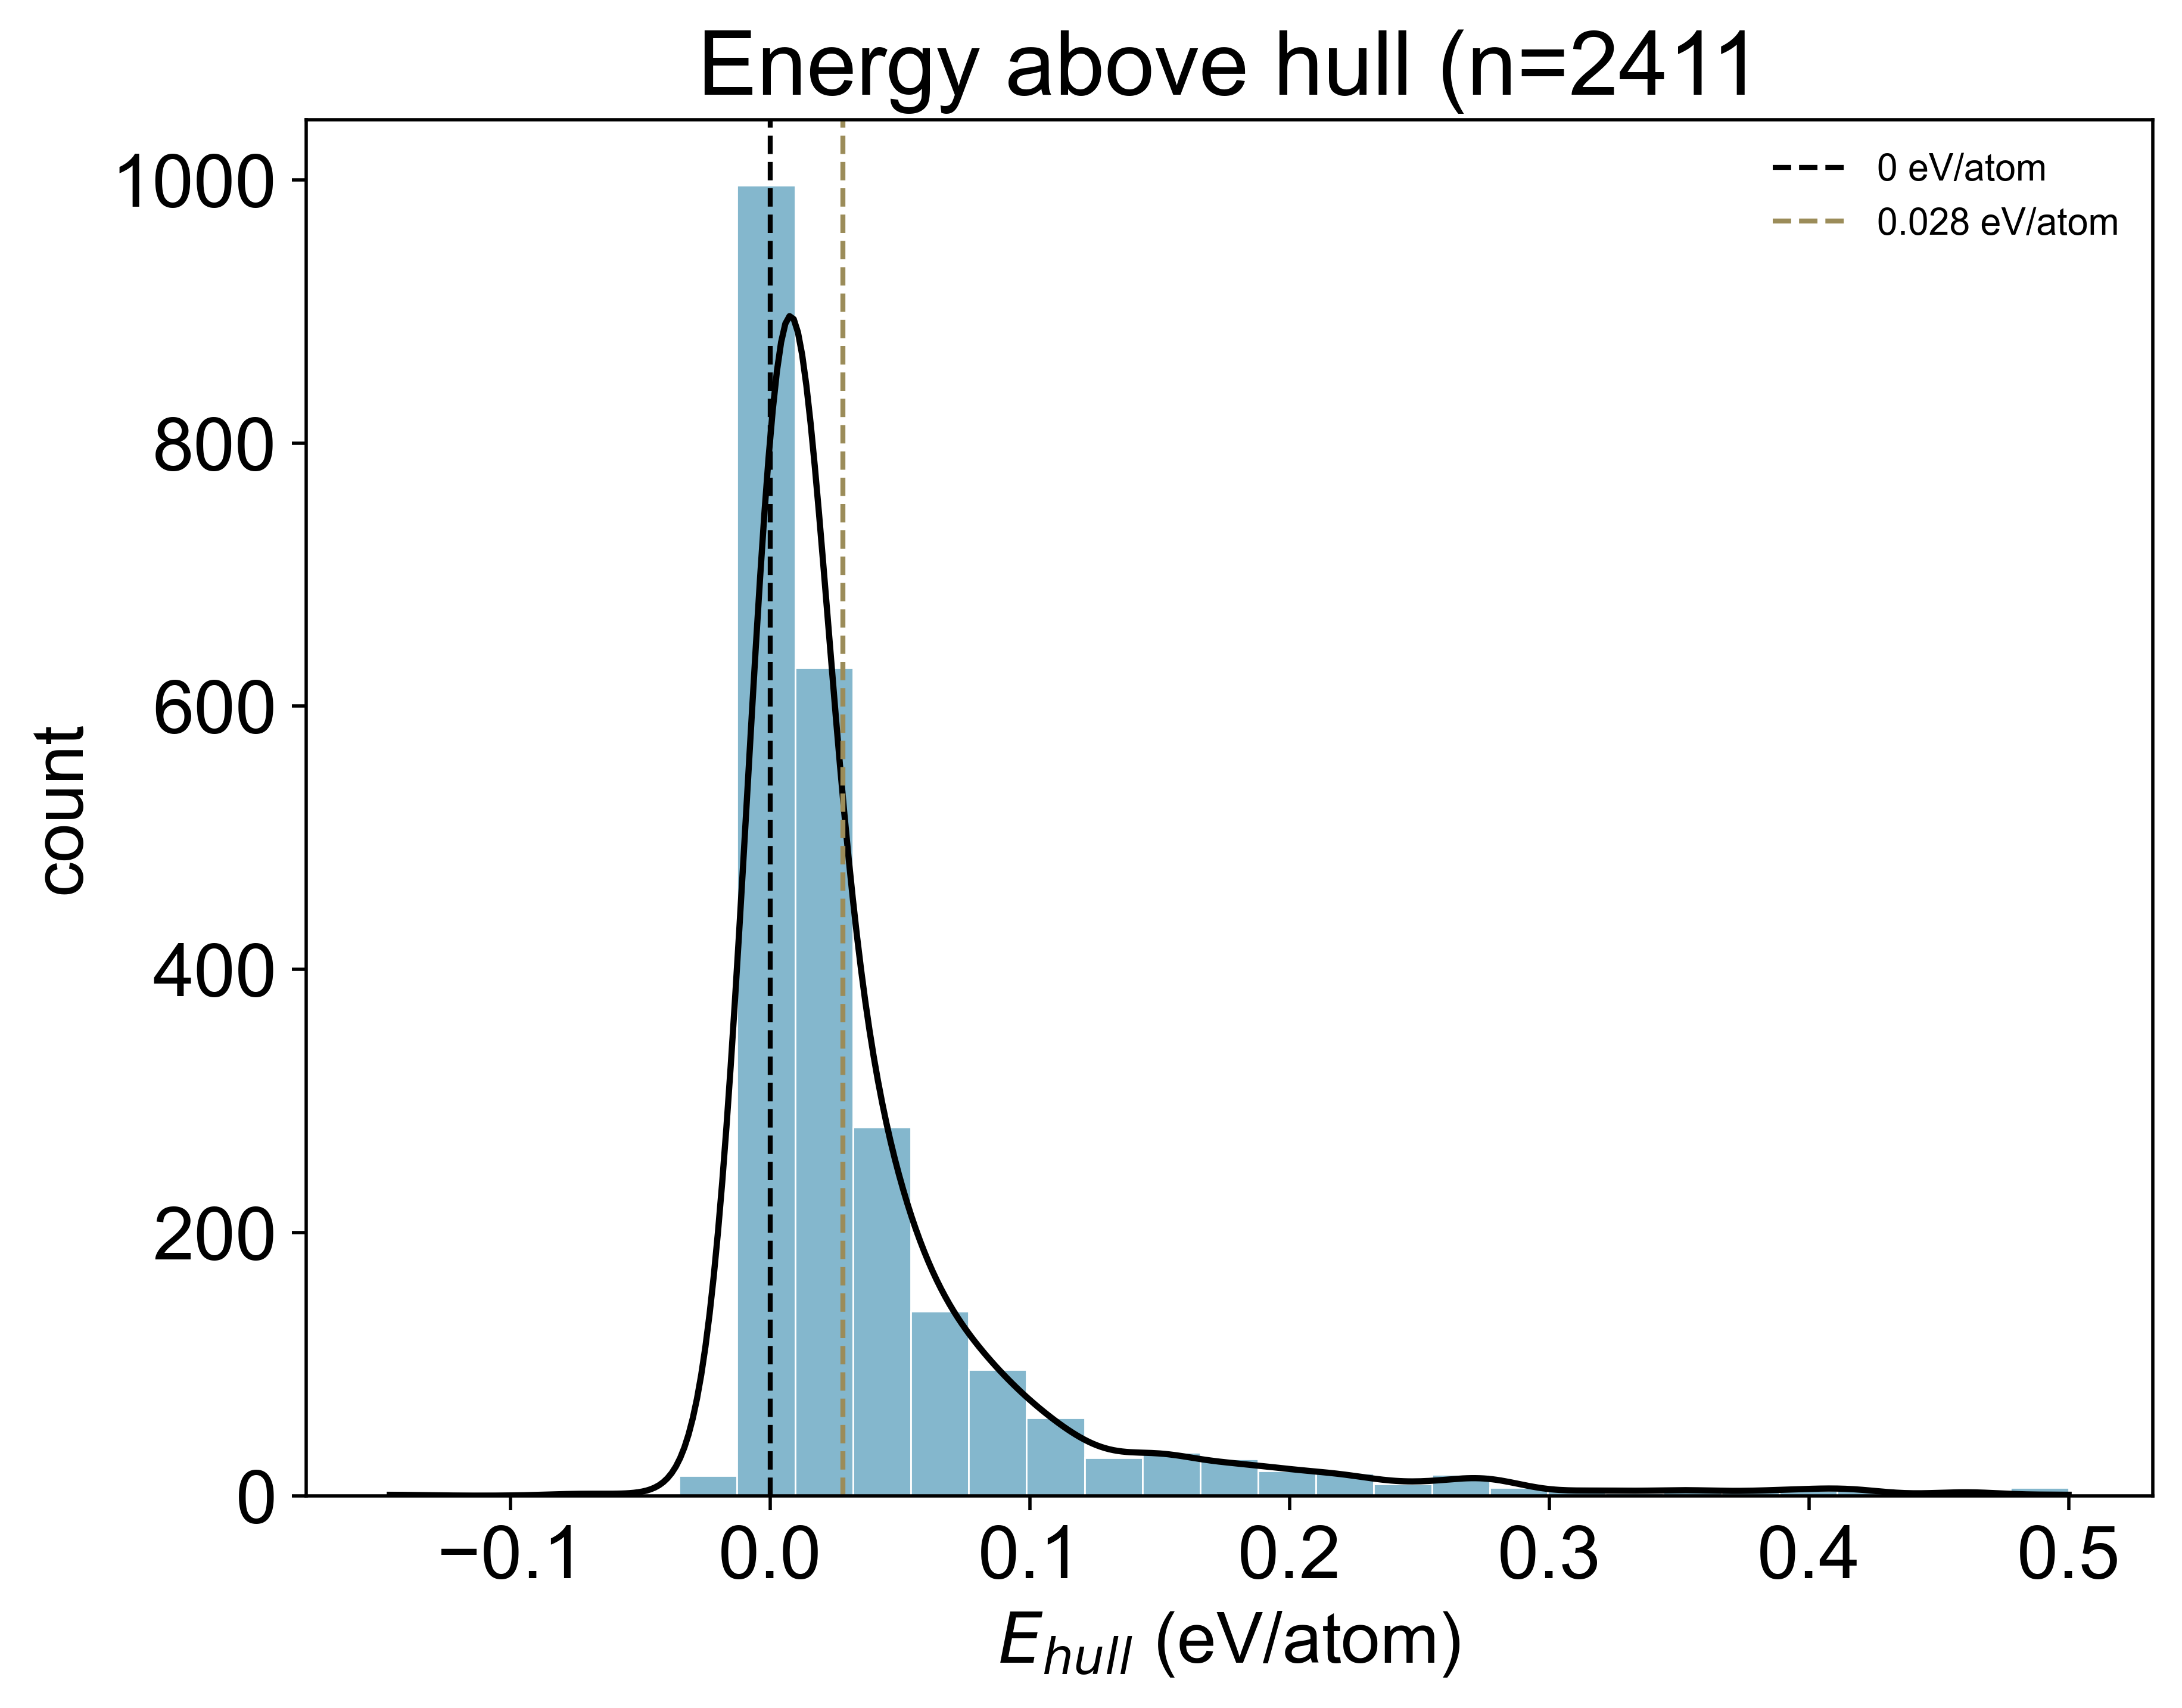

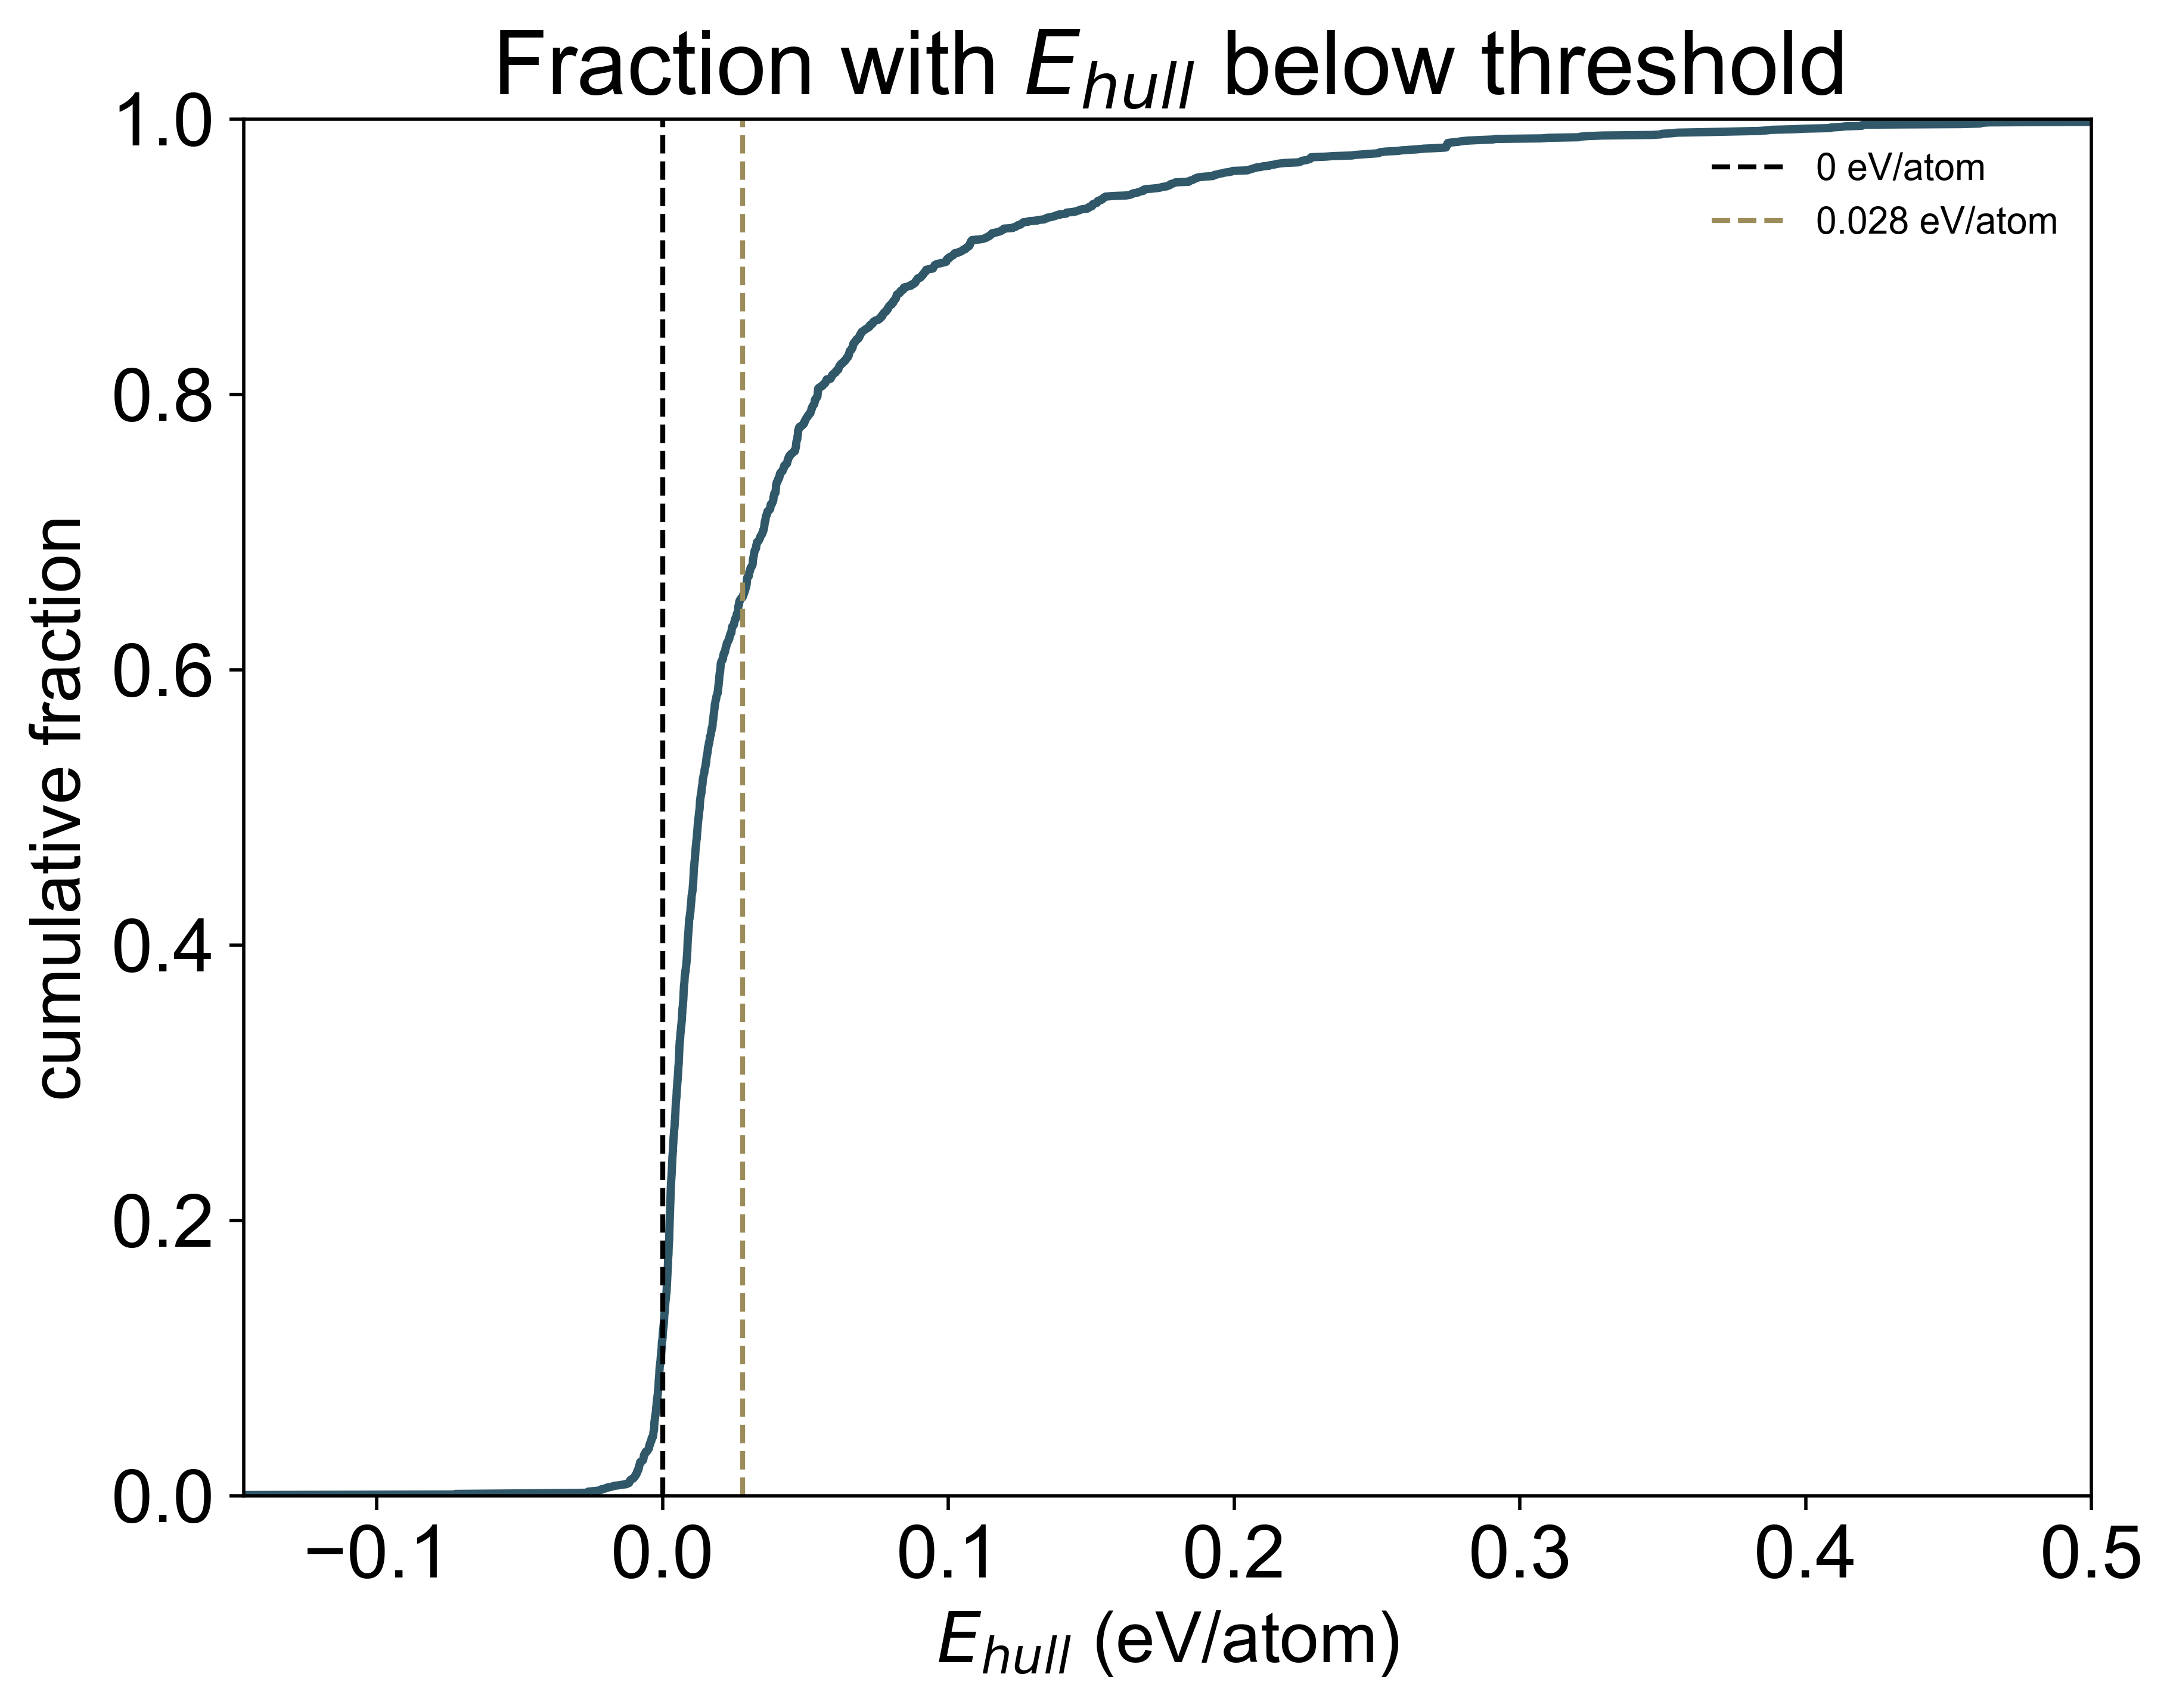

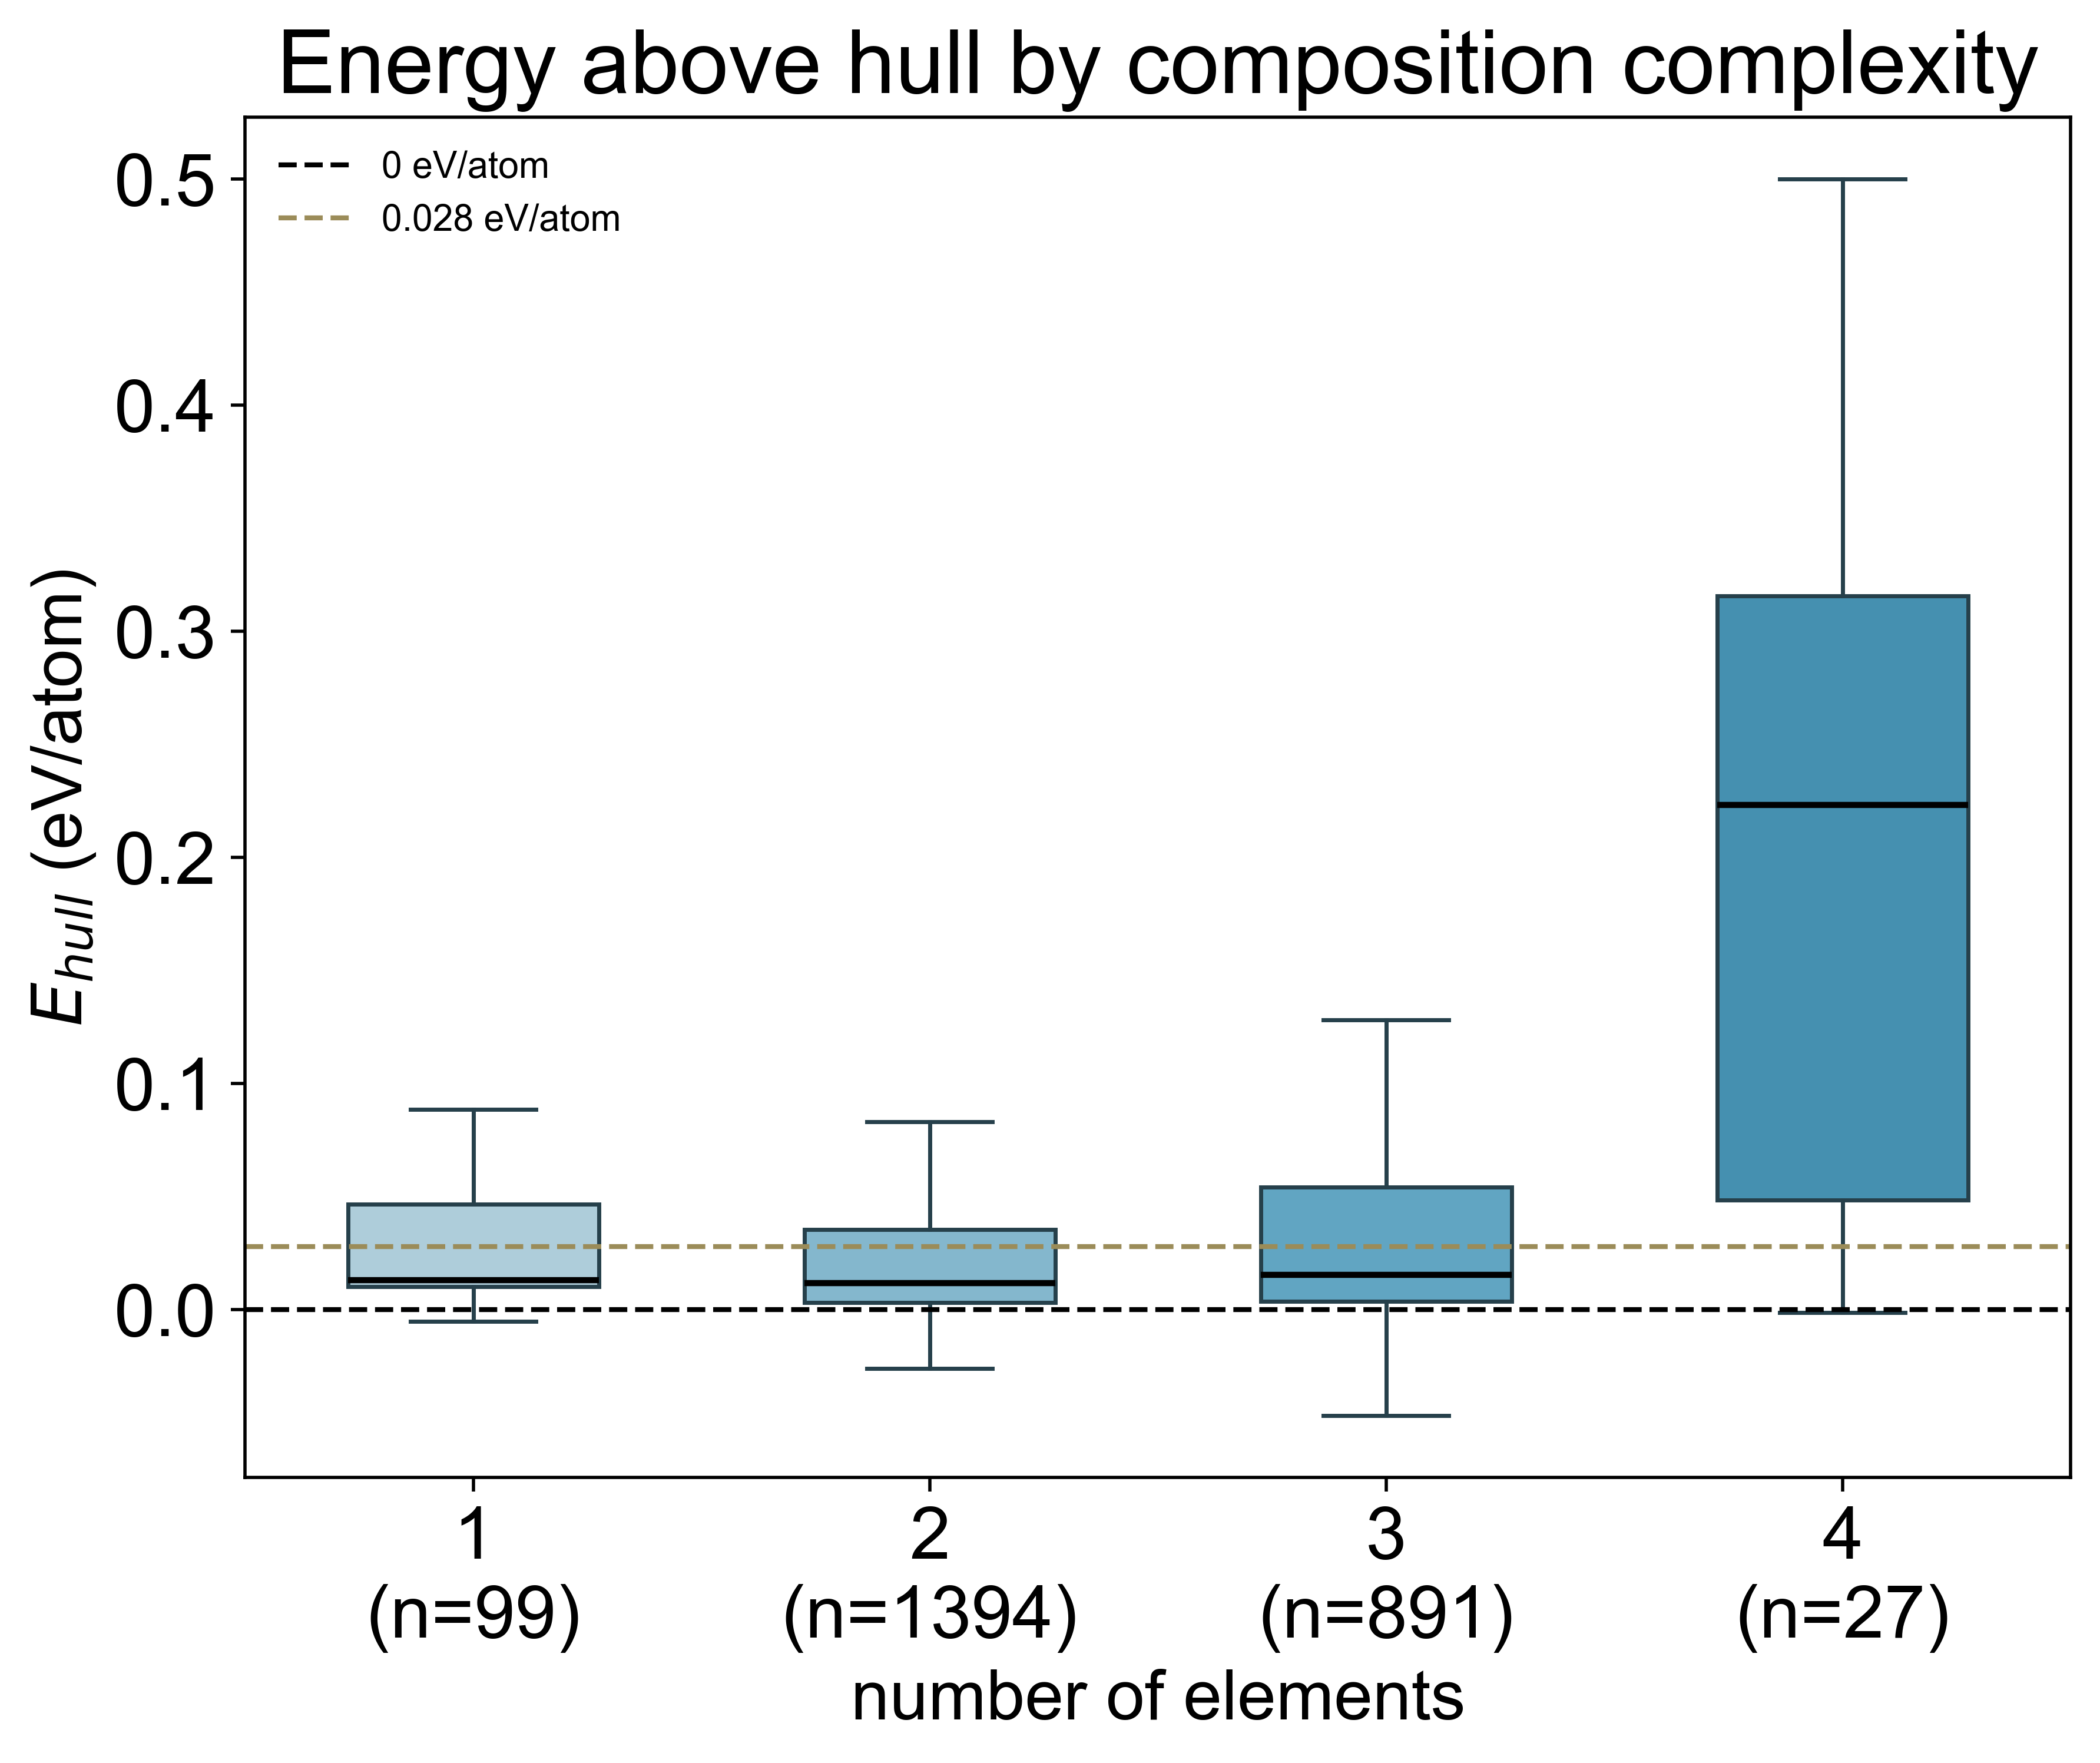

In [5]:
"""
E_hull summary for compute_ehull.py output. Paste into a notebook cell.

Four separate figures, each shown and saved at dpi=500 to OUT_DIR:
distribution, cumulative fraction, by number of elements, E_form vs E_hull.
"""
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymatgen.core import Composition
from scipy.stats import gaussian_kde

color3_ramp = ["#F5F8F9", "#E8EFF2", "#D8E9F0", "#AECDDA", "#84B7CD",
               "#61A5C2", "#4590B0", "#3A748D", "#305869", "#26404B", "#1A272D"]
HIST_COLOR = "#84B7CD"
KDE_COLOR = "black"
PDPT_HIST_COLOR = "#9B8C59"
PDPT_KDE_COLOR = "#1f3d6b"
TARGET_COLOR = "black"

# stability thresholds in eV/atom, with line colors
STABLE, METASTABLE = 0.0, 0.028
LINES = [(STABLE, "0", TARGET_COLOR),
         (METASTABLE, "0.028", PDPT_HIST_COLOR)]

OUT_DIR = Path("./figures")
DPI = 500


def load(csv):
    df = pd.read_csv(csv)
    df["n_elements"] = df["formula"].map(lambda f: len(Composition(f).elements))
    # decomposition into its own formula at 1.000 means MP has a phase at this composition
    df["known_comp"] = df.apply(
        lambda r: str(r["decomposition"]).split(":")[0] == r["formula"]
        and ";" not in str(r["decomposition"]), axis=1)
    return df


def summarize(df):
    e = df["e_above_hull"]
    print(f"{len(df)} structures")
    for label, mask in [("E_hull <= 0      (stable)", e <= STABLE),
                        ("E_hull <= 0.028    (stable or metastable)", e <= METASTABLE)]:
        print(f"  {label:45s} {mask.sum():6d}  {100 * mask.mean():5.1f}%")
    print(f"  median E_hull: {e.median():+.4f} eV/atom")
    print(f"  known composition in MP: {df['known_comp'].sum()} ({100 * df['known_comp'].mean():.1f}%)")
    print("  by number of elements:")
    for k, g in df.groupby("n_elements"):
        print(f"    {k}: n={len(g):5d}  <=0.1: {100 * (g['e_above_hull'] <= METASTABLE).mean():5.1f}%  "
              f"median {g['e_above_hull'].median():+.4f}")


def threshold_lines(ax, horizontal=False, legend=True):
    for x, lbl, c in LINES:
        (ax.axhline if horizontal else ax.axvline)(
            x, color=c, ls="--", lw=1.2, label=f"{lbl} eV/atom" if legend else None)
    if legend:
        ax.legend(fontsize=9, frameon=False)



def plot_distribution(df, xmax=0.5):
    e = df["e_above_hull"]
    lo = min(e.min(), -0.1)
    bins = np.linspace(lo, xmax, 30)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
    ax.hist(e.clip(upper=xmax), bins=bins, color=HIST_COLOR, edgecolor="white", lw=0.4)
    # KDE on values inside the axis range (clipped outliers would add a false bump),
    # scaled to histogram counts
    inside = e[e <= xmax]
    xs = np.linspace(lo, xmax, 400)
    ax.plot(xs, gaussian_kde(inside)(xs) * len(inside) * (bins[1] - bins[0]),
            color=KDE_COLOR, lw=1.5)
    over = (e > xmax).sum()
    threshold_lines(ax)
    ax.set_xlabel("$E_{hull}$ (eV/atom)")
    ax.set_ylabel("count")
    ax.set_title(f"Energy above hull (n={len(e)}")


def plot_cumulative(df, xmax=0.5):
    e = df["e_above_hull"]
    lo = min(e.min(), -0.1)
    xs = np.sort(e.values)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
    ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=color3_ramp[8], lw=2)
    threshold_lines(ax)
    ax.set_xlim(lo, xmax)
    ax.set_ylim(0, 1)
    ax.set_xlabel("$E_{hull}$ (eV/atom)")
    ax.set_ylabel("cumulative fraction")
    ax.set_title("Fraction with $E_{hull}$ below threshold")


def plot_by_elements(df, ymax=0.5):
    groups = sorted(df["n_elements"].unique())
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
    bp = ax.boxplot([df.loc[df["n_elements"] == k, "e_above_hull"].clip(upper=ymax) for k in groups],
                    tick_labels=[f"{k}\n(n={(df['n_elements'] == k).sum()})" for k in groups],
                    showfliers=False, patch_artist=True, widths=0.55)
    fills = color3_ramp[3:3 + len(groups)]
    for box, c in zip(bp["boxes"], fills):
        box.set(facecolor=c, edgecolor=color3_ramp[9])
    for part in ("whiskers", "caps"):
        for artist in bp[part]:
            artist.set(color=color3_ramp[9])
    for med in bp["medians"]:
        med.set(color=TARGET_COLOR, lw=1.5)
    threshold_lines(ax, horizontal=True)
    ax.set_xlabel("number of elements")
    ax.set_ylabel("$E_{hull}$ (eV/atom)")
    ax.set_title("Energy above hull by composition complexity")



df = load("./data/H_volcano/ehull.csv")
summarize(df)
plot_distribution(df)
plot_cumulative(df)
plot_by_elements(df)

2410 slabs
  median 1.896 J/m^2  (IQR 1.376 to 2.360)
  min -1.516  max 3.763
  gamma <= 2.84 J/m^2:   2204   91.5%


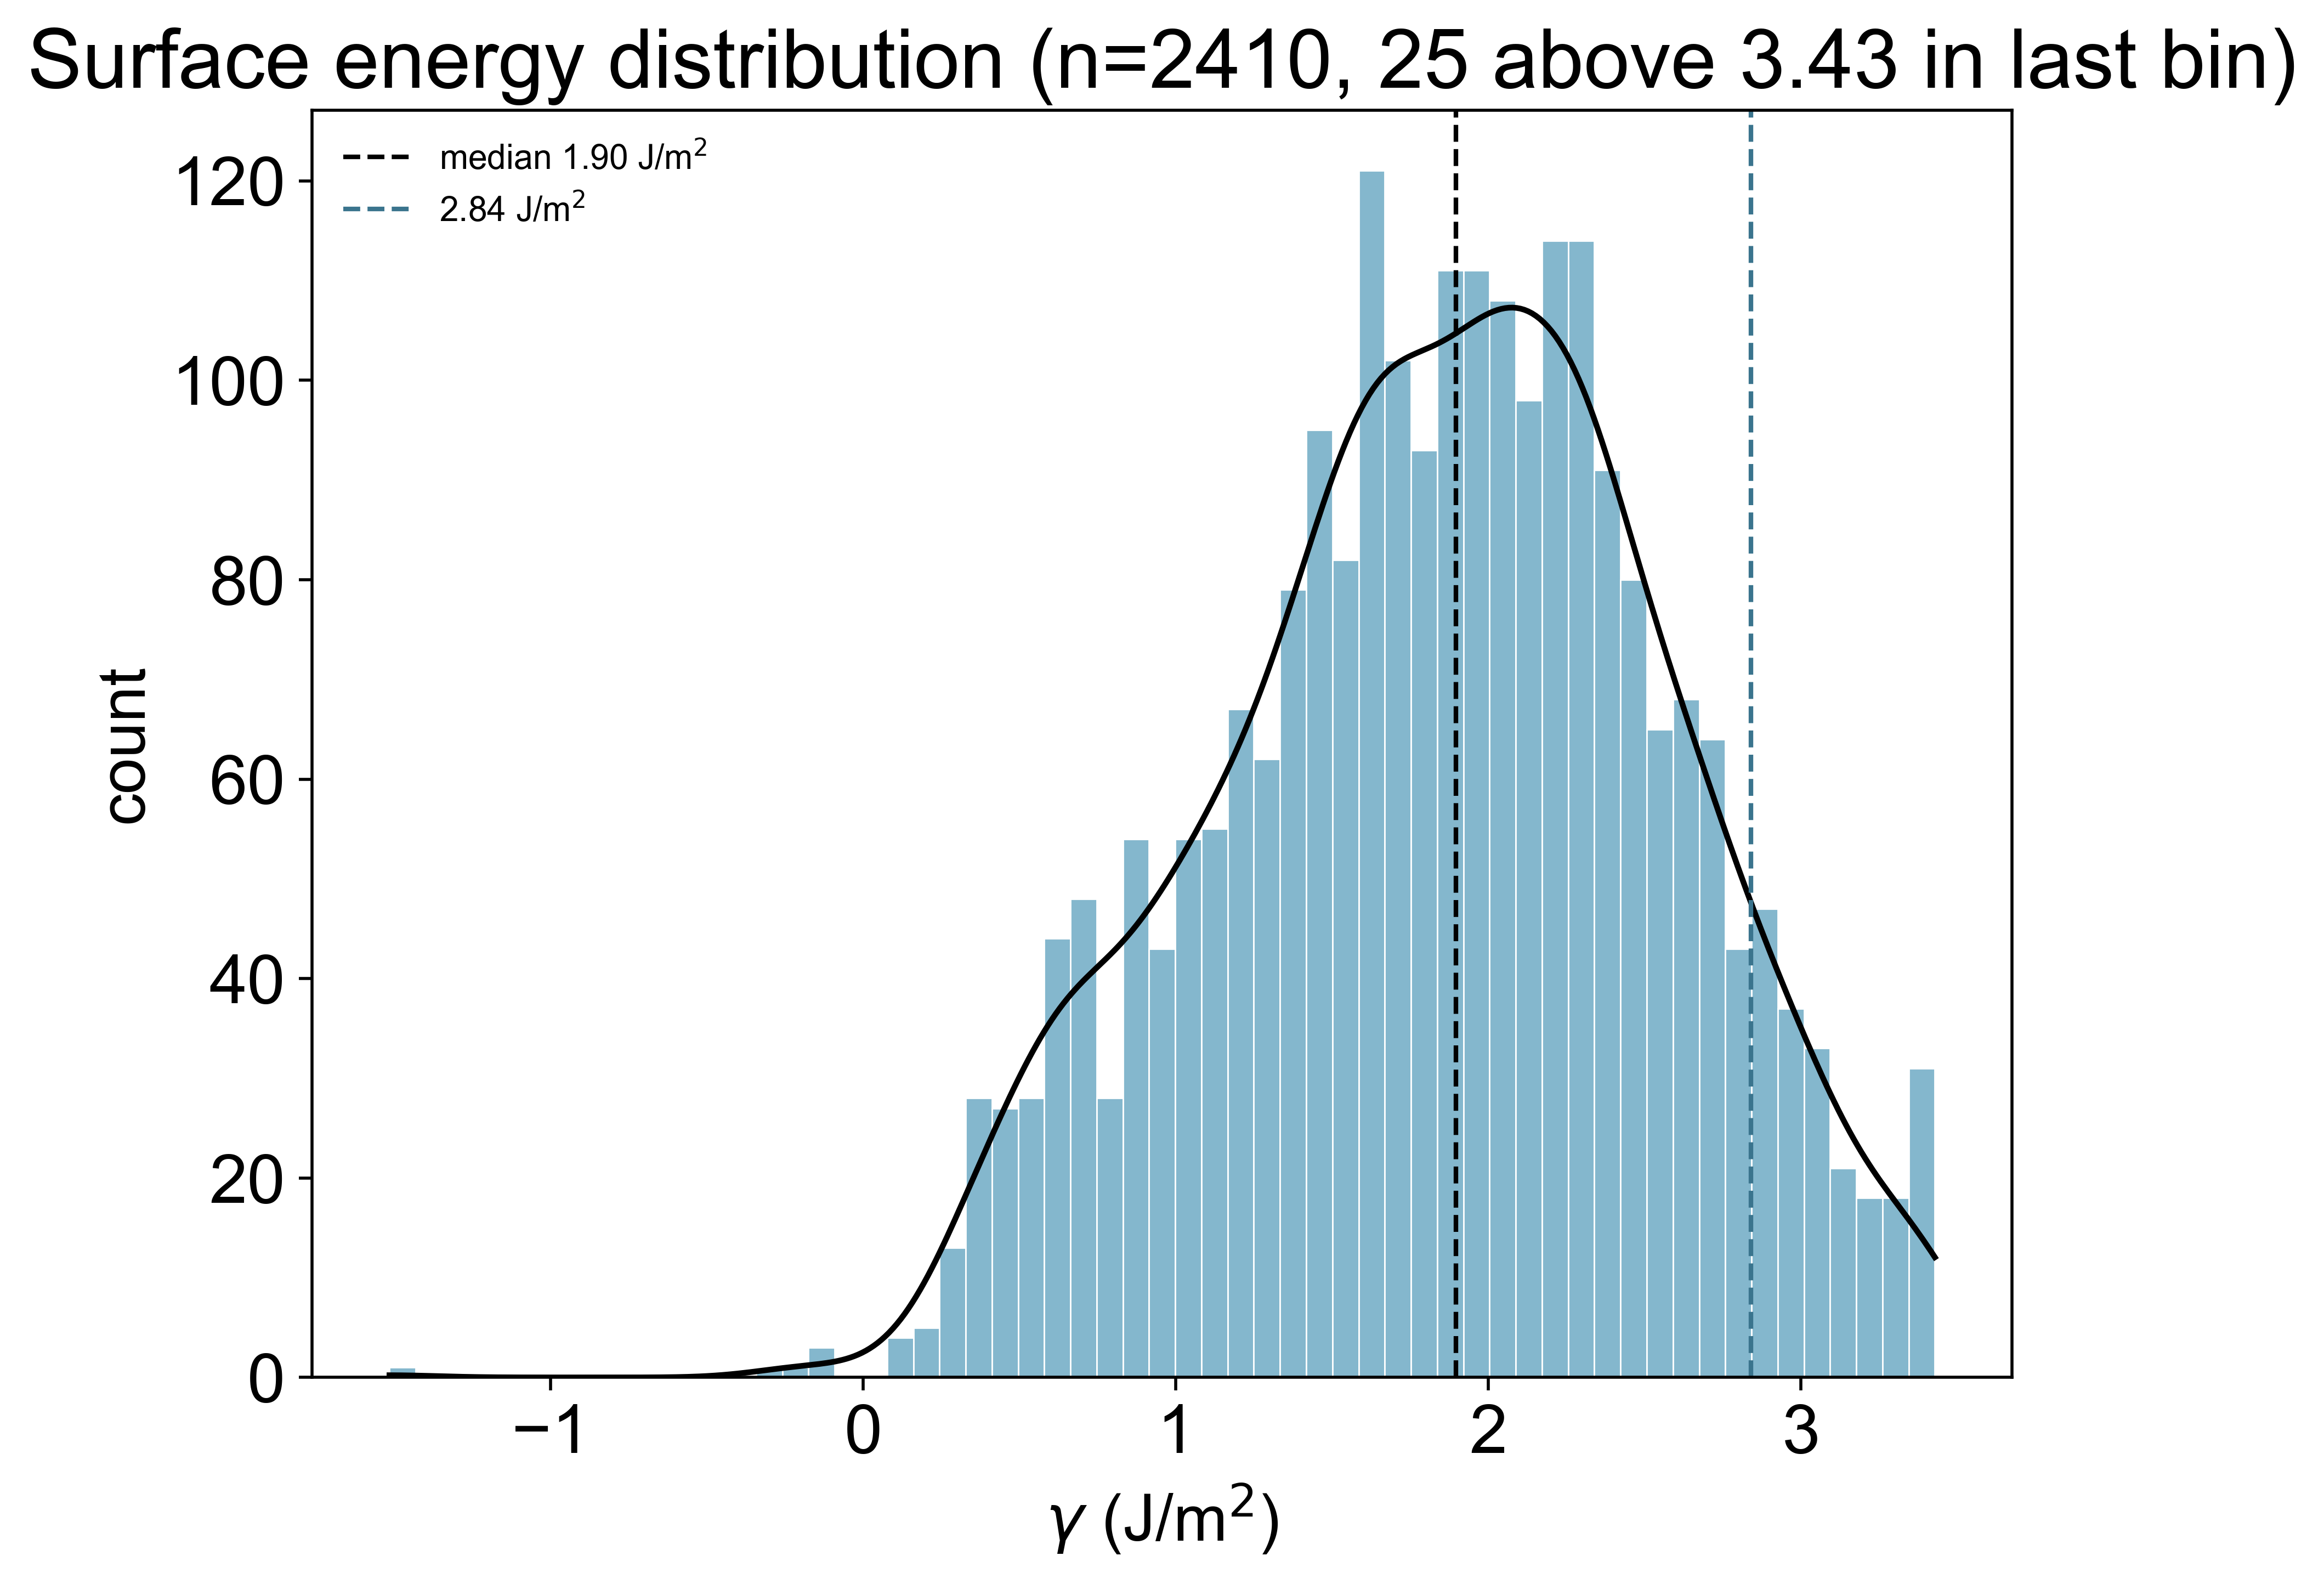

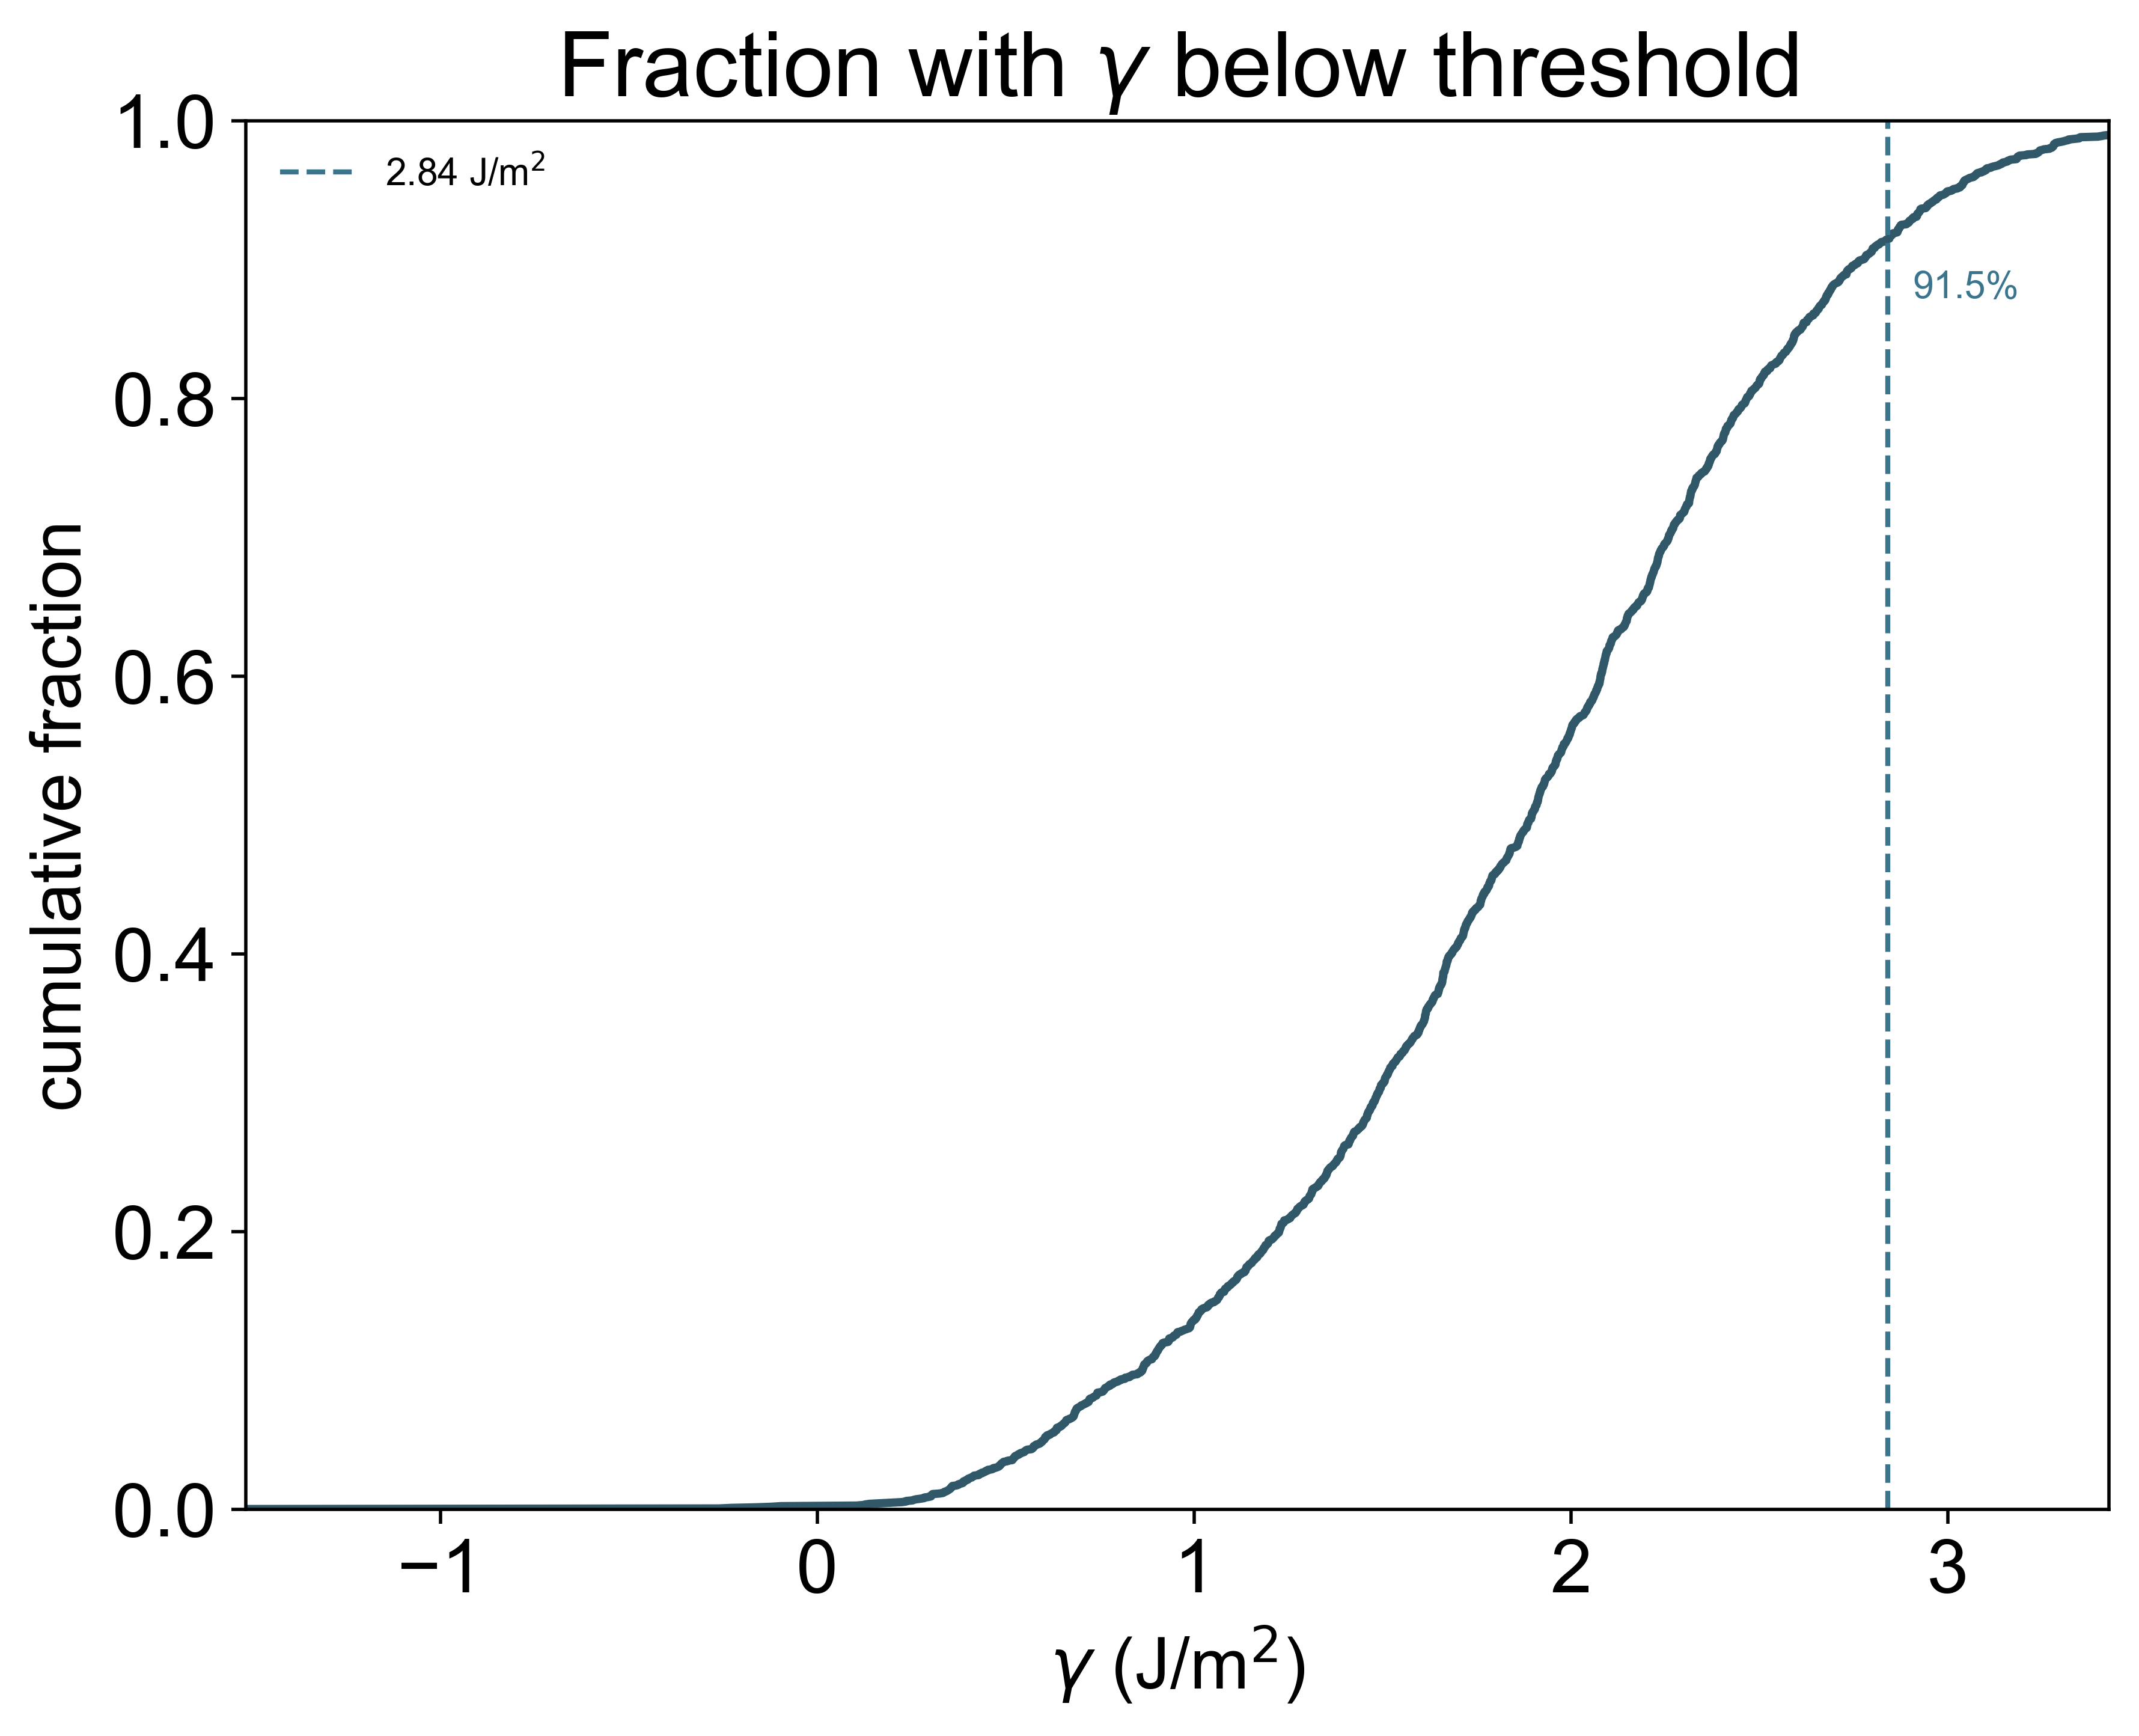

In [8]:
# ---------------- surface energy ----------------
EV_A2_TO_J_M2 = 16.0218
GAMMA_LINES = [(2.84, color3_ramp[7])]


def load_surf(csv):
    df = pd.read_csv(csv)
    df["gamma"] = df["surface_energy"] * EV_A2_TO_J_M2  # eV/A^2 -> J/m^2
    return df


def summarize_surf(df):
    g = df["gamma"]
    print(f"{len(df)} slabs")
    print(f"  median {g.median():.3f} J/m^2  (IQR {g.quantile(0.25):.3f} to {g.quantile(0.75):.3f})")
    print(f"  min {g.min():.3f}  max {g.max():.3f}")
    for x, _ in GAMMA_LINES:
        print(f"  gamma <= {x:g} J/m^2: {(g <= x).sum():6d}  {100 * (g <= x).mean():5.1f}%")
    if (neg := (g <= 0).sum()):
        print(f"  WARNING: {neg} slabs with gamma <= 0")


def plot_surf_distribution(df, xmax=None):
    g = df["gamma"]
    xmax = xmax or g.quantile(0.99)
    lo = min(g.min(), 0)
    bins = np.linspace(lo, xmax, 60)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
    ax.hist(g.clip(upper=xmax), bins=bins, color=HIST_COLOR, edgecolor="white", lw=0.4)
    xs = np.linspace(lo, xmax, 400)
    ax.plot(xs, gaussian_kde(g.clip(upper=xmax))(xs) * len(g) * (bins[1] - bins[0]),
            color=KDE_COLOR, lw=1.5)
    ax.axvline(g.median(), color=TARGET_COLOR, ls="--", lw=1.2,
               label=f"median {g.median():.2f} J/m$^2$")
    for x, c in GAMMA_LINES:
        ax.axvline(x, color=c, ls="--", lw=1.2, label=f"{x} J/m$^2$")
    ax.legend(fontsize=9, frameon=False)
    over = (g > xmax).sum()
    ax.set_xlabel(r"$\gamma$ (J/m$^2$)")
    ax.set_ylabel("count")
    ax.set_title(f"Surface energy distribution (n={len(g)}"
                 + (f", {over} above {xmax:.2f} in last bin)" if over else ")"))


def plot_surf_cumulative(df, xmax=None):
    g = df["gamma"]
    xmax = xmax or g.quantile(0.99)
    xs = np.sort(g.values)
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
    ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=color3_ramp[8], lw=2)
    for x, c in GAMMA_LINES:
        frac = (g <= x).mean()
        ax.axvline(x, color=c, ls="--", lw=1.2, label=f"{x} J/m$^2$")
        ax.annotate(f"{100 * frac:.1f}%", (x, frac), textcoords="offset points",
                    xytext=(6, -14), fontsize=9, color=c)
    ax.legend(fontsize=9, frameon=False)
    ax.set_xlim(min(g.min(), 0), xmax)
    ax.set_ylim(0, 1)
    ax.set_xlabel(r"$\gamma$ (J/m$^2$)")
    ax.set_ylabel("cumulative fraction")
    ax.set_title(r"Fraction with $\gamma$ below threshold")


sdf = load_surf("./data/H_volcano/surface_energy.csv")  # set your path
summarize_surf(sdf)
plot_surf_distribution(sdf)
plot_surf_cumulative(sdf)

2411 E_hull rows, 2404 surface rows (gamma > 0), 2404 matched
  in MP: 1511  novel: 893
Metastable (E_hull <= 0.028 eV/atom, gamma < 2.84 J/m^2): 1413/2404 (58.8%)
  composition of metastable set: in MP 1091 (77.2%), novel 322 (22.8%)
  in MP pass rate: 1091/1511 (72.2%)
  novel pass rate: 322/893 (36.1%)
  plotting 2161/2404; 243 outside [-40, 100] meV/atom omitted


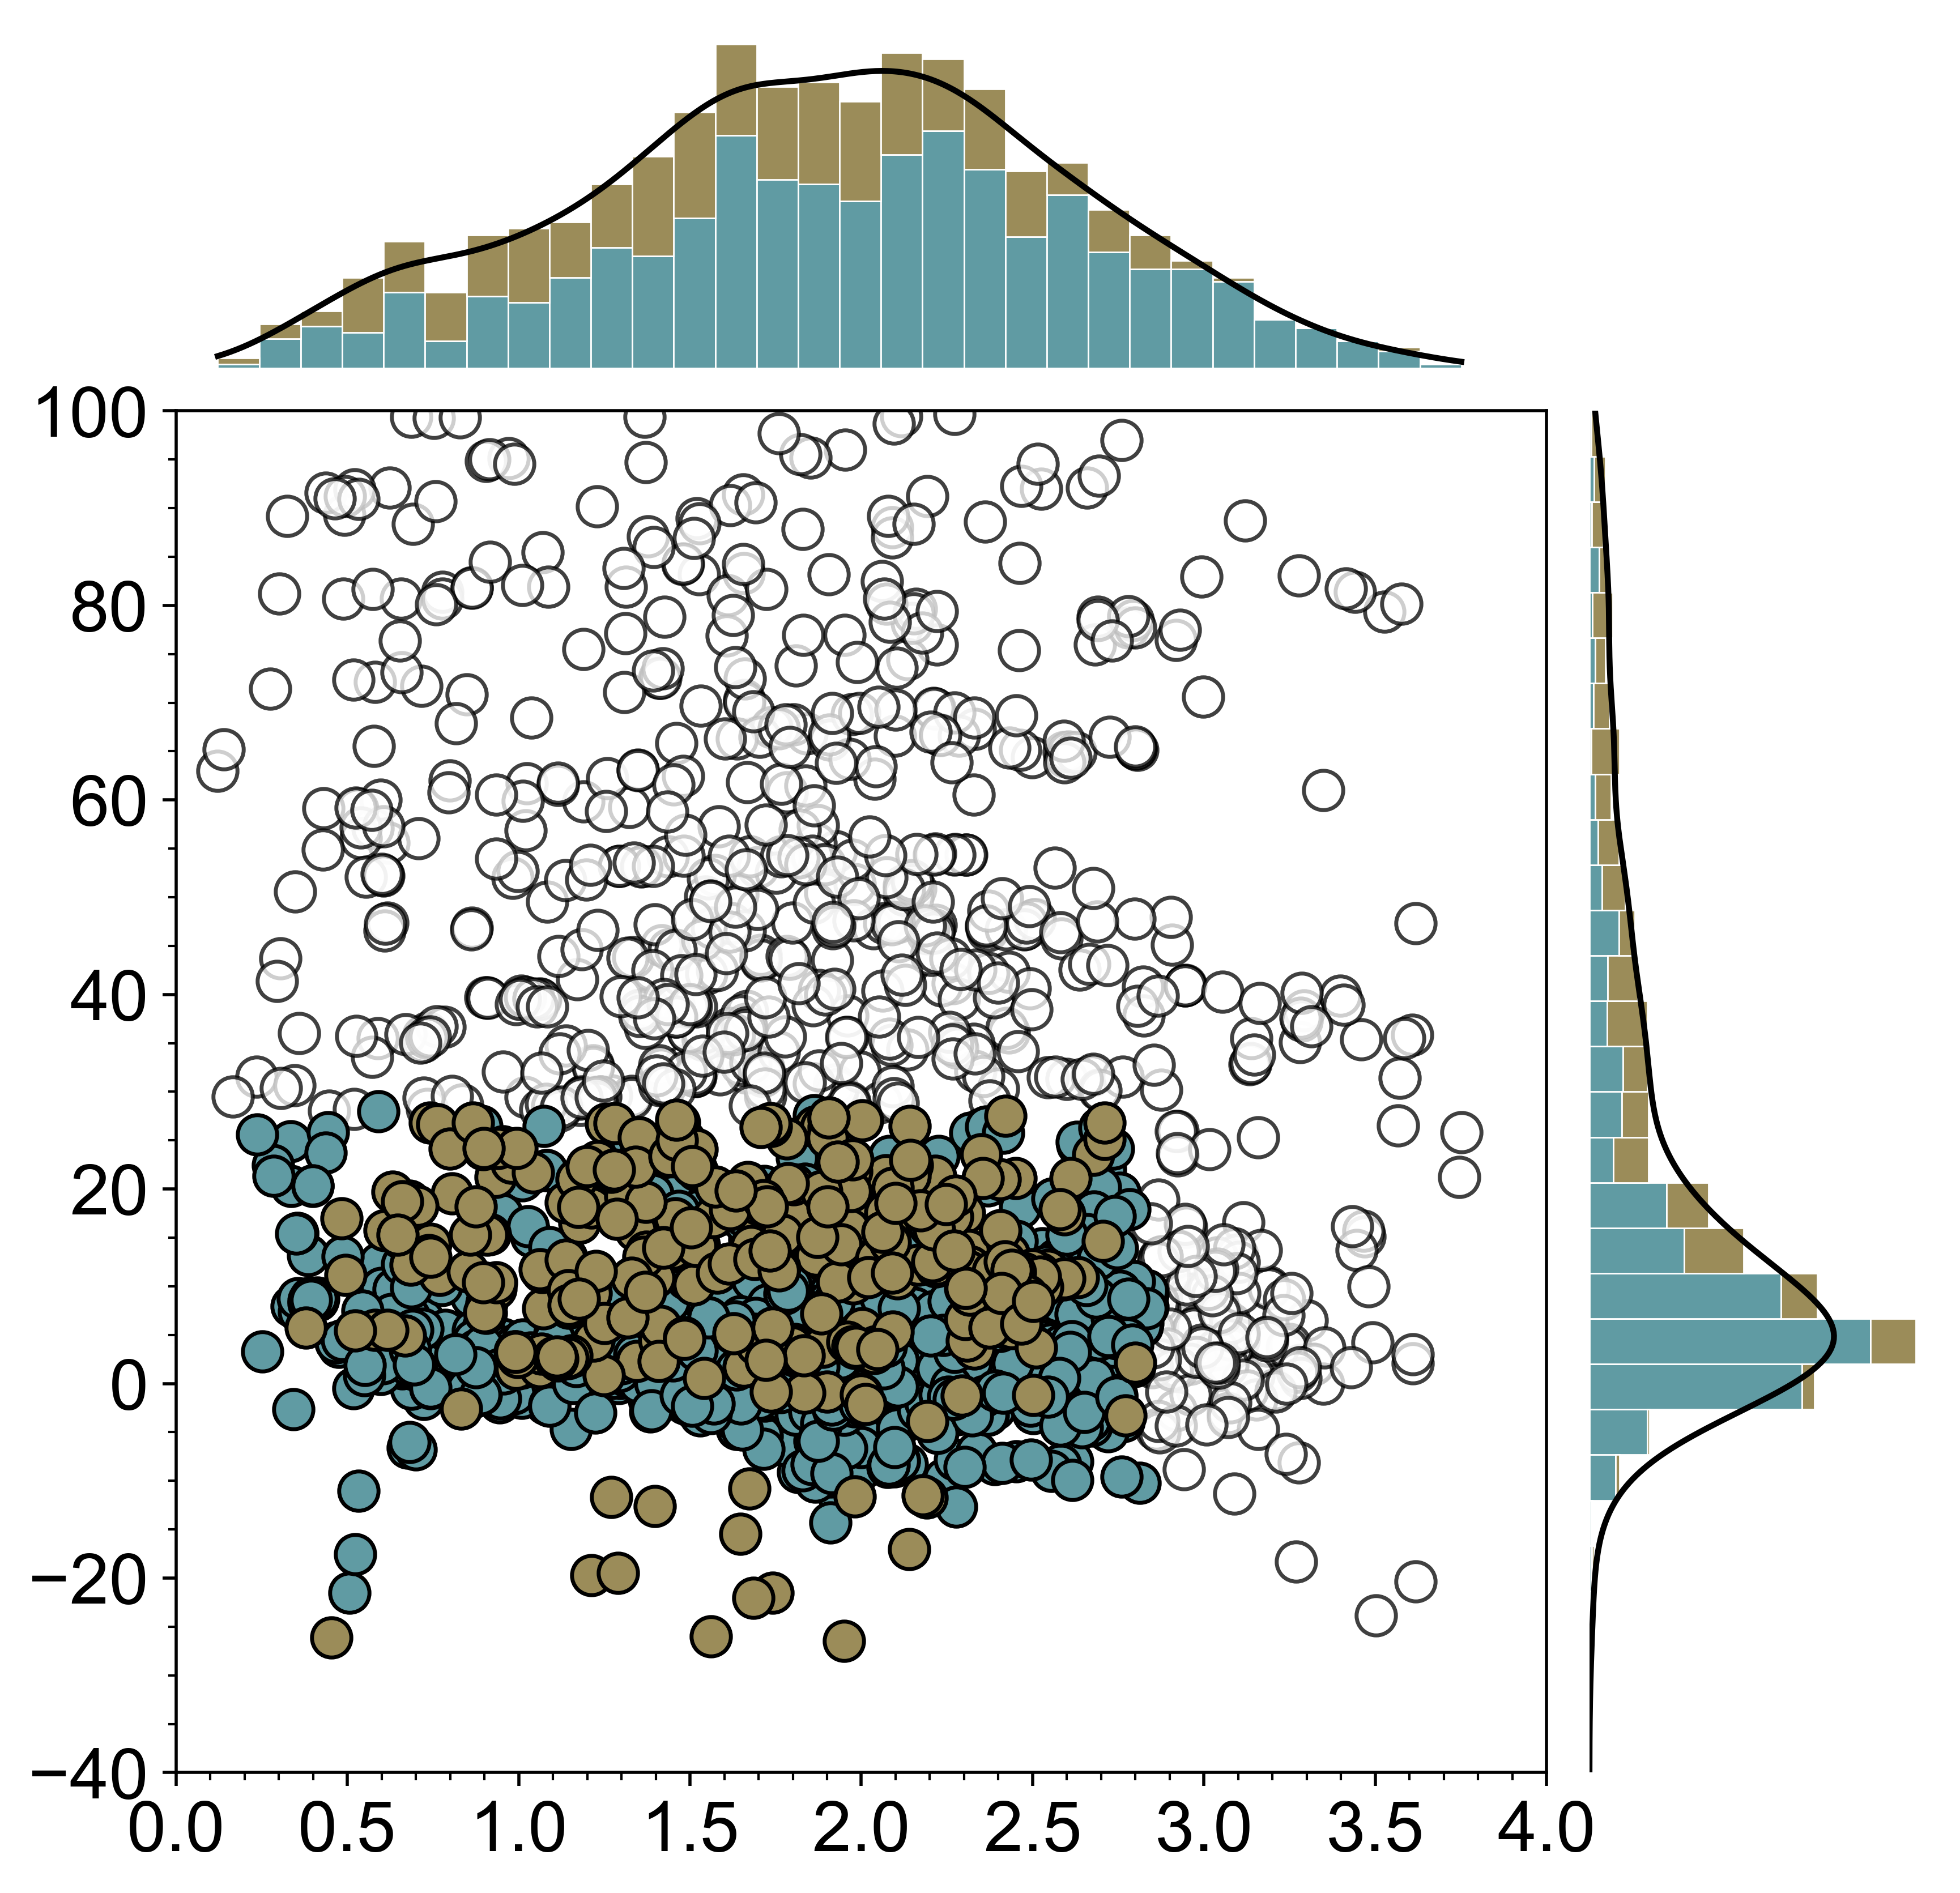

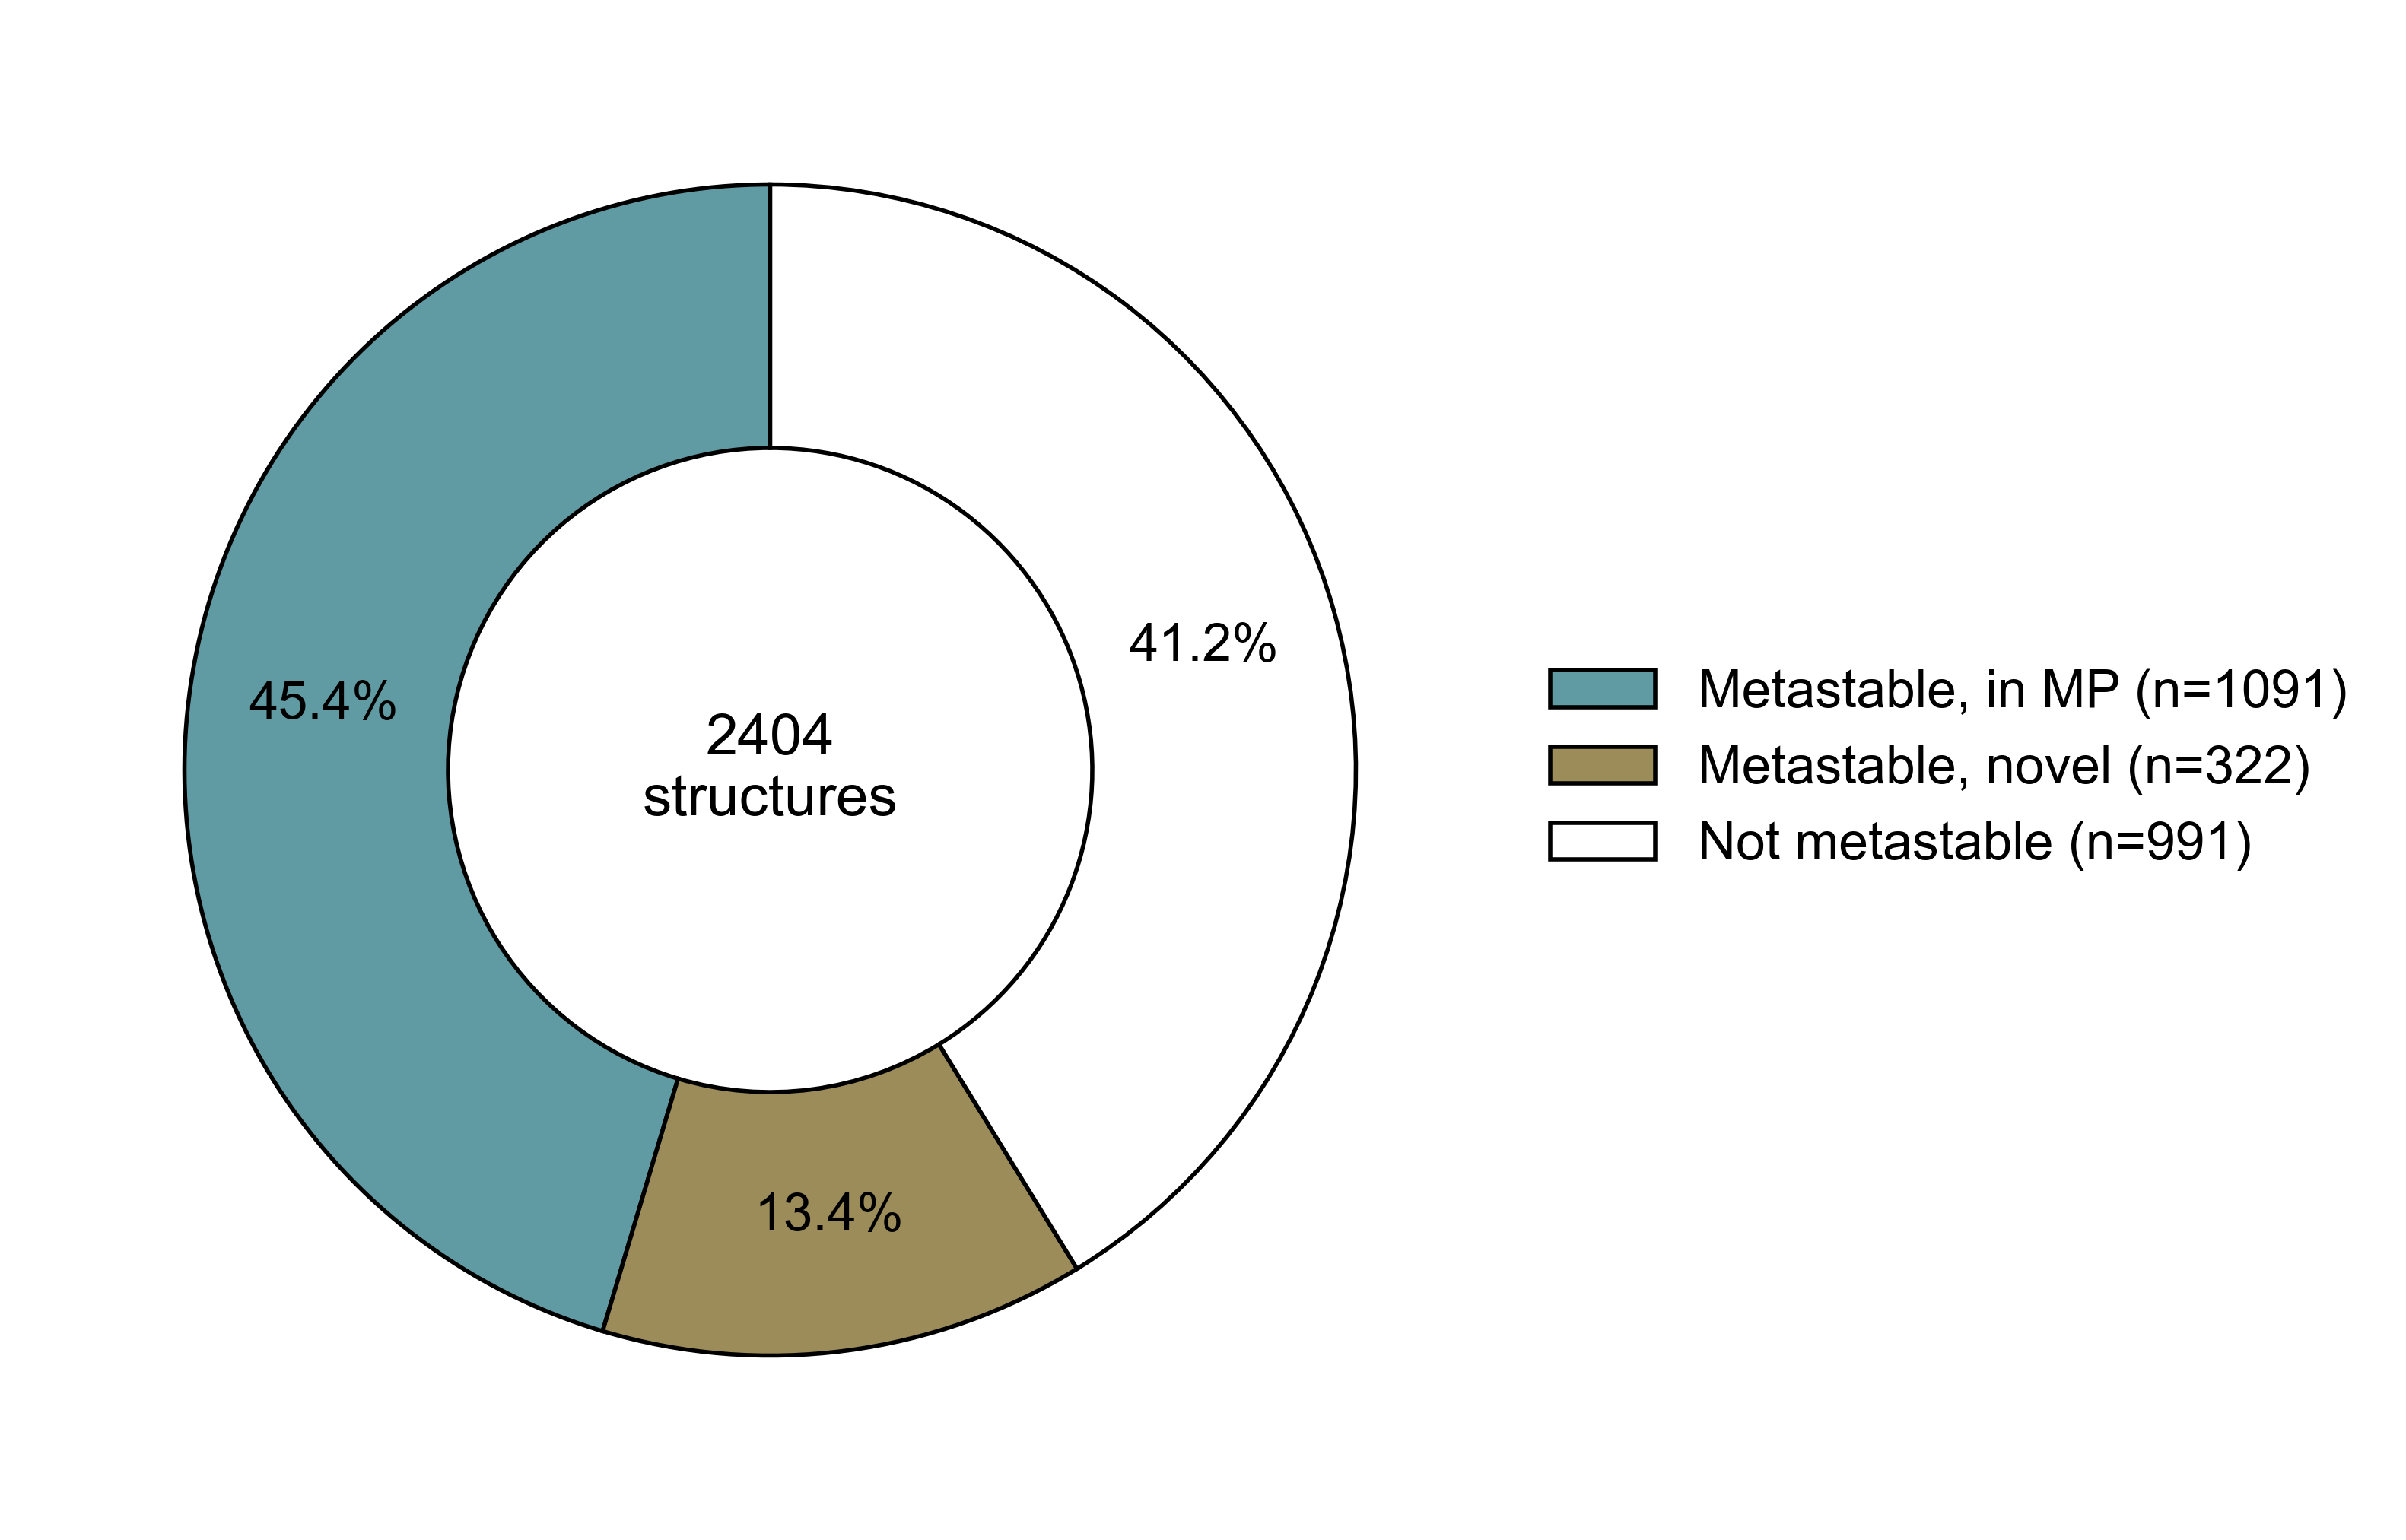

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from pymatgen.core import Composition
from scipy.stats import gaussian_kde

HIST_COLOR = "#84B7CD"
PDPT_HIST_COLOR = "#9B8C59"
IN_MP_COLOR = "#609ba3"
NOVEL_COLOR = PDPT_HIST_COLOR
KDE_COLOR = "black"

EV_A2_TO_J_M2 = 16.0218

# Metastability defined as having a surface energy below 2.84 J/m2 and E_hull below 0.028 eV/atom (95% confidence)
EHULL_CUT = 0.028  # eV/atom
GAMMA_CUT = 2.84   # J/m^2


def load_merged(ehull_csv, surf_csv):
    eh = pd.read_csv(ehull_csv)[["name", "formula", "e_above_hull", "decomposition"]]
    sf = pd.read_csv(surf_csv)
    sf = sf[sf["surface_energy"] > 0].copy()
    sf["gamma"] = sf["surface_energy"] * EV_A2_TO_J_M2
    df = eh.merge(sf[["name", "gamma"]], on="name", how="inner")
    print(f"{len(eh)} E_hull rows, {len(sf)} surface rows (gamma > 0), {len(df)} matched")
    return df


def add_in_mp(df):
    """in_mp = True if the decomposition is a single MP phase with the same composition."""
    def in_mp(row):
        phases = row["decomposition"].split("; ")
        return (len(phases) == 1 and Composition(phases[0].split(":")[0]).reduced_formula
                == Composition(row["formula"]).reduced_formula)
    return df.assign(in_mp=df.apply(in_mp, axis=1))


def hist_kde(ax, x_mp, x_novel, bins, horizontal=False):
    x_all = np.concatenate([np.asarray(x_mp), np.asarray(x_novel)])
    edges = np.histogram_bin_edges(x_all, bins=bins)
    ax.hist([x_mp, x_novel], bins=edges, stacked=True,
            orientation="horizontal" if horizontal else "vertical",
            color=[IN_MP_COLOR, NOVEL_COLOR], edgecolor="white", lw=0.4)
    xs = np.linspace(edges[0], edges[-1], 400)
    ys = gaussian_kde(x_all)(xs) * len(x_all) * (edges[1] - edges[0])
    ax.plot(*((ys, xs) if horizontal else (xs, ys)), color=KDE_COLOR, lw=1.5)


def plot_joint_scatter(df, ymin=-40, ymax=100, ystep=20, xstep=0.5, alpha_out=0.75):
    g = df["gamma"]
    e = 1000 * df["e_above_hull"]  # meV/atom
    inr = e.between(ymin, ymax)
    mp = df["in_mp"].astype(bool)
    print(f"  plotting {inr.sum()}/{len(df)}; {(~inr).sum()} outside [{ymin}, {ymax}] meV/atom omitted")
    xmin, xmax = 0, xstep * np.ceil(g[inr].max() / xstep)  # round up to the next tick

    fig = plt.figure(figsize=(8, 8), dpi=500)
    gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                          wspace=0.05, hspace=0.05)
    ax = fig.add_subplot(gs[1, 0])
    axx = fig.add_subplot(gs[0, 0], sharex=ax)
    axy = fig.add_subplot(gs[1, 1], sharey=ax)

    meta = (df["e_above_hull"] <= EHULL_CUT) & (g < GAMMA_CUT)
    for grp, color, label in [(mp, IN_MP_COLOR, "In MP"), (~mp, NOVEL_COLOR, "Novel")]:
        ax.scatter(g[grp & inr & meta], e[grp & inr & meta], s=100, color=color,
                   edgecolor="black", label=label, zorder=3)
        ax.scatter(g[grp & inr & ~meta], e[grp & inr & ~meta], s=100, color="white",
                   edgecolor="black", alpha=alpha_out, zorder=2)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.xaxis.set_major_locator(MultipleLocator(xstep))
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())

    hist_kde(axx, g[mp & inr], g[~mp & inr], bins=30)
    hist_kde(axy, e[mp & inr], e[~mp & inr], bins=np.linspace(ymin, ymax, 31), horizontal=True)
    for a in (axx, axy):
        a.set_frame_on(False)
        a.tick_params(which="both", left=False, bottom=False, labelleft=False, labelbottom=False)
    
    #save_flat_svg(fig=fig, path=f"fig6/panel/gammaa_ehull.svg")

def plot_breakdown_donut(df, figsize=(5, 5)):
    mp = df["in_mp"].astype(bool)
    meta = (df["e_above_hull"] <= EHULL_CUT) & (df["gamma"] < GAMMA_CUT)
    counts = [(meta & mp).sum(), (meta & ~mp).sum(), (~meta).sum()]
    labels = ["Metastable, in MP", "Metastable, novel", "Not metastable"]
    fig, ax = plt.subplots(figsize=figsize, dpi=500)
    ax.set_aspect("equal")
    ax.pie(counts, colors=[IN_MP_COLOR, NOVEL_COLOR, "white"], startangle=90,
           wedgeprops=dict(width=0.45, edgecolor="black", lw=0.8),
           autopct=lambda p: f"{p:.1f}%", pctdistance=0.77, textprops=dict(fontsize=10))
    ax.text(0, 0, f"{len(df)}\nstructures", ha="center", va="center", fontsize=11)
    ax.legend([f"{l} (n={c})" for l, c in zip(labels, counts)],
              loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=10)
    # save_flat_svg(fig=fig, path="fig6/panel/breakdown_donut.svg")


def summarize_metastable(df):
    meta = (df["e_above_hull"] <= EHULL_CUT) & (df["gamma"] < GAMMA_CUT)
    mp = df["in_mp"].astype(bool)
    print(f"Metastable (E_hull <= {EHULL_CUT} eV/atom, gamma < {GAMMA_CUT} J/m^2): "
          f"{meta.sum()}/{len(df)} ({100 * meta.mean():.1f}%)")
    print(f"  composition of metastable set: in MP {(meta & mp).sum()} "
          f"({100 * (meta & mp).sum() / meta.sum():.1f}%), "
          f"novel {(meta & ~mp).sum()} ({100 * (meta & ~mp).sum() / meta.sum():.1f}%)")
    print(f"  in MP pass rate: {(meta & mp).sum()}/{mp.sum()} ({100 * meta[mp].mean():.1f}%)")
    print(f"  novel pass rate: {(meta & ~mp).sum()}/{(~mp).sum()} ({100 * meta[~mp].mean():.1f}%)")


jdf = load_merged("./data/H_volcano/ehull.csv",
                  "./data/H_volcano/surface_energy.csv")  # set your surface path
jdf = add_in_mp(jdf)
print(f"  in MP: {jdf['in_mp'].sum()}  novel: {(~jdf['in_mp']).sum()}")
summarize_metastable(jdf)
plot_joint_scatter(jdf)
plot_breakdown_donut(jdf)

In [10]:
def metastable_names(df, elements=None):
    meta = (df["e_above_hull"] <= EHULL_CUT) & (df["gamma"] < GAMMA_CUT)
    sub = df[meta]
    if elements:
        has_el = sub["formula"].apply(
            lambda f: bool({el.symbol for el in Composition(f).elements} & set(elements)))
        sub = sub[has_el]
    return sub["name"].tolist()


meta_names = metastable_names(jdf)
meta_ptpd_names = metastable_names(jdf, elements={"Pt", "Pd"})
print(f"metastable: {len(meta_names)}  metastable with Pt/Pd: {len(meta_ptpd_names)}")

Path("./data/H_volcano/metastable_names.txt").write_text("\n".join(meta_names))
Path("./data/H_volcano/metastable_ptpd_names.txt").write_text("\n".join(meta_ptpd_names))

metastable: 1413  metastable with Pt/Pd: 503


2961

# ENR

In [ ]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

LINE_COLOR = "black"
REGION_COLOR = "red"
HIST_COLOR = "#808080"
KDE_COLOR = "black"
DEFAULT_COLOR = "#B0B0B0"

# Elements to highlight, in priority order (first match wins if a formula has more than one)
HIGHLIGHT_ELEMENTS = ["Ti", "Al", "Rh", "Ru", "Co", "Fe", "Ni", "Cu"]
HIGHLIGHT_COLORS = {
    "Ti": "#4C72B0",
    "Al": "#DD8452",
    "Rh": "#55A868",
    "Ru": "#C44E52",
    "Co": "#8172B2",
    "Fe": "#937860",
    "Ni": "#DA8BC3",
    "Cu": "#CCB974",
}

# Original high-activity lines from paper (N_ads = slope * O_ads + intercept, paper reference)
LEFT_SLOPE, LEFT_INT = 1.91, 5.47
RIGHT_SLOPE, RIGHT_INT = 1.70, 1.65
N_SHIFT = 5.189
O_SHIFT = 2.846

plt.rcParams.update({"font.size": 14})


def save_flat_svg(fig, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig.savefig(path, format="svg", dpi=500, bbox_inches="tight")
    print(f"Saved plot to {path}")


def load_binding_energies(file):
    df = pd.read_csv(file)
    for col in ("n_computed_binding_E", "o_computed_binding_E", "reduced_formula"):
        if col not in df.columns:
            raise KeyError(f"Expected column '{col}' not found in CSV")
    df = df.dropna(subset=["n_computed_binding_E", "o_computed_binding_E"])
    if df.empty:
        raise ValueError("No valid (non-NaN) binding energy rows found")
    return df


def formula_elements(formula):
    return set(re.findall(r"[A-Z][a-z]?", formula))


def formula_to_color(formula):
    present = formula_elements(formula)
    for element in HIGHLIGHT_ELEMENTS:
        if element in present:
            return HIGHLIGHT_COLORS[element]
    return DEFAULT_COLOR


def add_marginal_hist(ax, data, orientation, bin_range, n_bins=20):
    counts, bin_edges, _ = ax.hist(
        data, bins=n_bins, range=bin_range, density=True, orientation=orientation,
        color=HIST_COLOR, alpha=0.6, edgecolor="white",
    )
    if len(data) > 1:
        kde = gaussian_kde(data)
        x = np.linspace(bin_range[0], bin_range[1], 300)
        y = kde(x)
        if orientation == "vertical":
            ax.plot(x, y, color=KDE_COLOR, linewidth=1.5)
        else:
            ax.plot(y, x, color=KDE_COLOR, linewidth=1.5)
    ax.axis("off")


def plot_n_vs_o(df, output_path):
    n_E = df["n_computed_binding_E"].to_numpy() - N_SHIFT
    o_E = df["o_computed_binding_E"].to_numpy() - O_SHIFT
    colors = df["reduced_formula"].apply(formula_to_color).to_numpy()

    lo = min(n_E.min(), o_E.min()) - 0.2
    hi = max(n_E.max(), o_E.max()) + 0.2

    fig = plt.figure(figsize=(6, 6), dpi=500)
    gs = fig.add_gridspec(
        2, 2, width_ratios=(5, 1), height_ratios=(1, 5),
        left=0.12, right=0.98, bottom=0.1, top=0.98,
        wspace=0.03, hspace=0.03,
    )
    ax = fig.add_subplot(gs[1, 0])
    ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

    o_line = np.linspace(lo, hi, 100)
    n_left = LEFT_SLOPE * o_line + LEFT_INT
    n_right = RIGHT_SLOPE * o_line + RIGHT_INT

    ax.fill_between(o_line, n_left, n_right, color=REGION_COLOR, alpha=0.2, zorder=0)
    ax.plot(o_line, n_left, color=REGION_COLOR, linestyle="--", linewidth=1.2, zorder=1)
    ax.plot(o_line, n_right, color=REGION_COLOR, linestyle="--", linewidth=1.2, zorder=1)

    ax.scatter(o_E, n_E, color=colors, alpha=0.7, edgecolor="black", linewidth=0.5, s=100, zorder=2)

    # Legend handles for highlighted elements + "Other"
    handles = [
        plt.scatter([], [], color=HIGHLIGHT_COLORS[el], edgecolor="black", linewidth=0.5, s=100, label=el)
        for el in HIGHLIGHT_ELEMENTS
    ]
    handles.append(plt.scatter([], [], color=DEFAULT_COLOR, edgecolor="black", linewidth=0.5, s=100, label="Other"))
    handles.append(plt.Rectangle((0, 0), 1, 1, color=REGION_COLOR, alpha=0.2))

    ax.set_xlabel("O computed binding energy (eV)")
    ax.set_ylabel("N computed binding energy (eV)")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=handles, frameon=False, fontsize=10, loc="upper left", ncol=1)

    add_marginal_hist(ax_top, o_E, "vertical", (lo, hi))
    add_marginal_hist(ax_right, n_E, "horizontal", (lo, hi))

    save_flat_svg(fig, output_path)
    plt.show()


file = "./data/ENR_volcano/n_o_matches.csv"
output_path = "./fig5/panel/n_vs_o_binding_energy.svg"

df = load_binding_energies(file)
plot_n_vs_o(df, output_path)

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BAR_COLOR = "#4C72B0"

plt.rcParams.update({"font.size": 14})


def save_flat_svg(fig, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig.savefig(path, format="svg", dpi=500, bbox_inches="tight")
    print(f"Saved plot to {path}")


def load_element_counts(file):
    df = pd.read_csv(file)
    for col in ("Element", "Count"):
        if col not in df.columns:
            raise KeyError(f"Expected column '{col}' not found in CSV")
    return df.sort_values("Count", ascending=False)


def plot_element_counts(df, output_path):
    fig, ax = plt.subplots(figsize=(12, 5), dpi=500)

    ax.bar(df["Element"], df["Count"], color=BAR_COLOR, edgecolor="black", linewidth=0.5)

    ax.set_xlabel("Element")
    ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)
    plt.xticks(rotation=90)

    fig.tight_layout()
    #save_flat_svg(fig, output_path)
    plt.show()


file = "./data/ENR_volcano/n_o_element_count.csv"
output_path = "./fig5/panel/n_o_element_count.svg"

df = load_element_counts(file)
plot_element_counts(df, output_path)